# Vellore Institute of Technology (VIT)
## School of Computer Science and Engineering
### Machine Learning Lab (MACSE504) - Mini-Project Phase 1 (Part A)
- **Student Name:** Vedant Nimkar
- **Register Number:** 26MML0045
- **Assigned Question:** Question 3: Used Car Valuation & Elasticity Analysis using Regularized Regression
- **Component:** Part A: Exploratory Data Analysis & Preprocessing
- **Live Web Application:** [https://cardekho-autovaluate.vercel.app](https://cardekho-autovaluate.vercel.app)
- **GitHub Repository:** [https://github.com/adminsharpcode/cardekho-autovaluate](https://github.com/adminsharpcode/cardekho-autovaluate)

---
### Project Overview & Objectives
This project focuses on building an automated econometric valuation model for a used car marketplace. Resale prices are estimated based on characteristics like age, mileage, fuel type, transmission, engine capacity, power, and dealer type.

Dataset: `Car details v3.csv` (8,128 vehicle listings).


In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, scipy.stats as stats
import matplotlib.pyplot as plt, seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Libraries successfully imported.")


Libraries successfully imported.


### 1. Feature Extraction & Data Preprocessing
Load CarDekho dataset, calculate vehicle age ($2020 - \text{year}$), clean strings in technical attributes (`mileage`, `engine`, `max_power`), and apply brand-conditioned median imputation.


In [2]:
df = pd.read_csv('Car details v3.csv')
REFERENCE_YEAR = 2020
df['vehicle_age'] = REFERENCE_YEAR - df['year']
df['brand'] = df['name'].apply(lambda x: str(x).split()[0].strip())

df['mileage_val'] = df['mileage'].str.extract(r'([0-9.]+)').astype(float)
df.loc[df['mileage_val'] == 0, 'mileage_val'] = np.nan
df['engine_val'] = df['engine'].str.extract(r'([0-9.]+)').astype(float)
df['max_power_val'] = df['max_power'].str.extract(r'([0-9.]+)').astype(float)
df.loc[df['max_power_val'] == 0, 'max_power_val'] = np.nan

for col in ['mileage_val', 'engine_val', 'max_power_val', 'seats']:
    df[col] = df.groupby('brand')[col].transform(lambda s: s.fillna(s.median()))
    df[col] = df[col].fillna(df[col].median())

print(f"Missing values after brand-conditioned imputation: {df[['mileage_val', 'engine_val', 'max_power_val', 'seats']].isnull().sum().sum()}")


Missing values after brand-conditioned imputation: 0


### 2. Price Distribution & Log-Transformation
Analyze target skewness and apply natural log-transformation ($\\ln(\\text{selling\\_price})$) to stabilize variance and normalize luxury car residuals.


In [3]:
df['log_selling_price'] = np.log(df['selling_price'])
print(f"Raw Price Skewness : +{df['selling_price'].skew():.4f} (Heavy right tail)")
print(f"Log Price Skewness : +{df['log_selling_price'].skew():.4f} (Near-symmetric normal)")


Raw Price Skewness : +4.1935 (Heavy right tail)
Log Price Skewness : +0.2233 (Near-symmetric normal)


<Figure size 1600x1100 with 4 Axes>


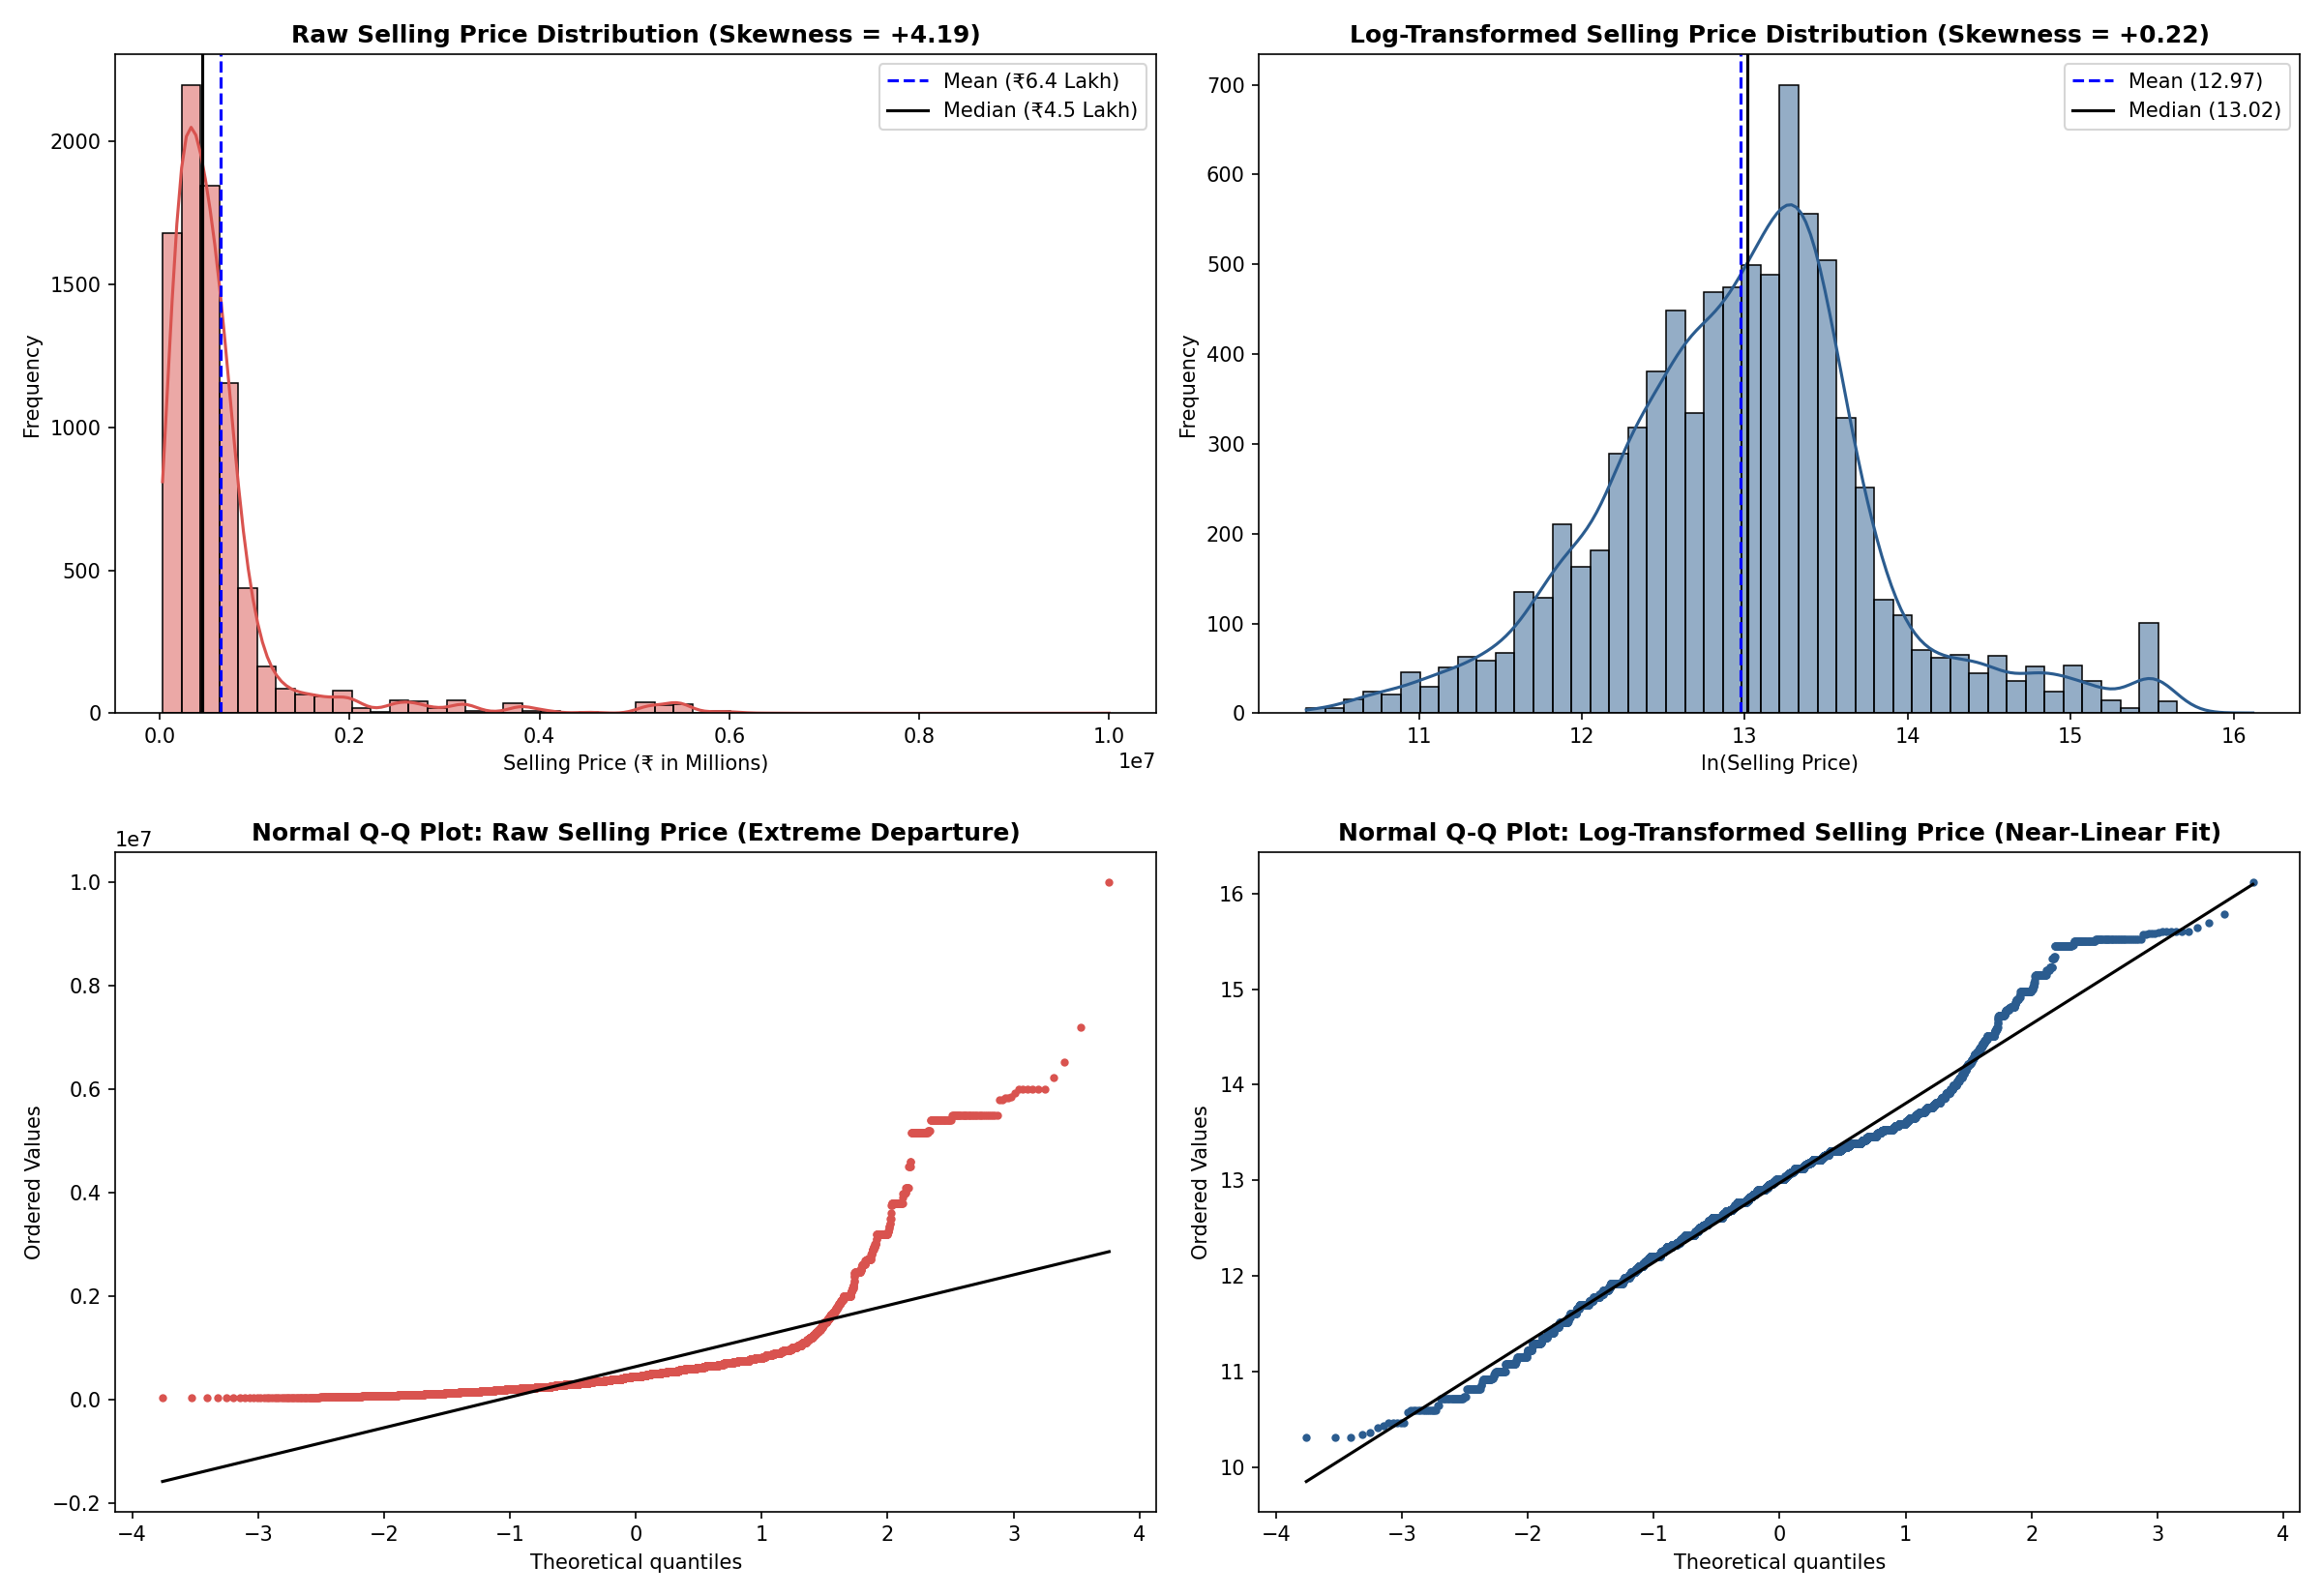

In [4]:
# Visualizing Raw vs Log Price Distributions & Normal Q-Q Plots


### 3. Visualizing Price Trends, Depreciation Curves & Fuel Distributions


Pearson Correlation between km_driven and log_selling_price : -0.2527


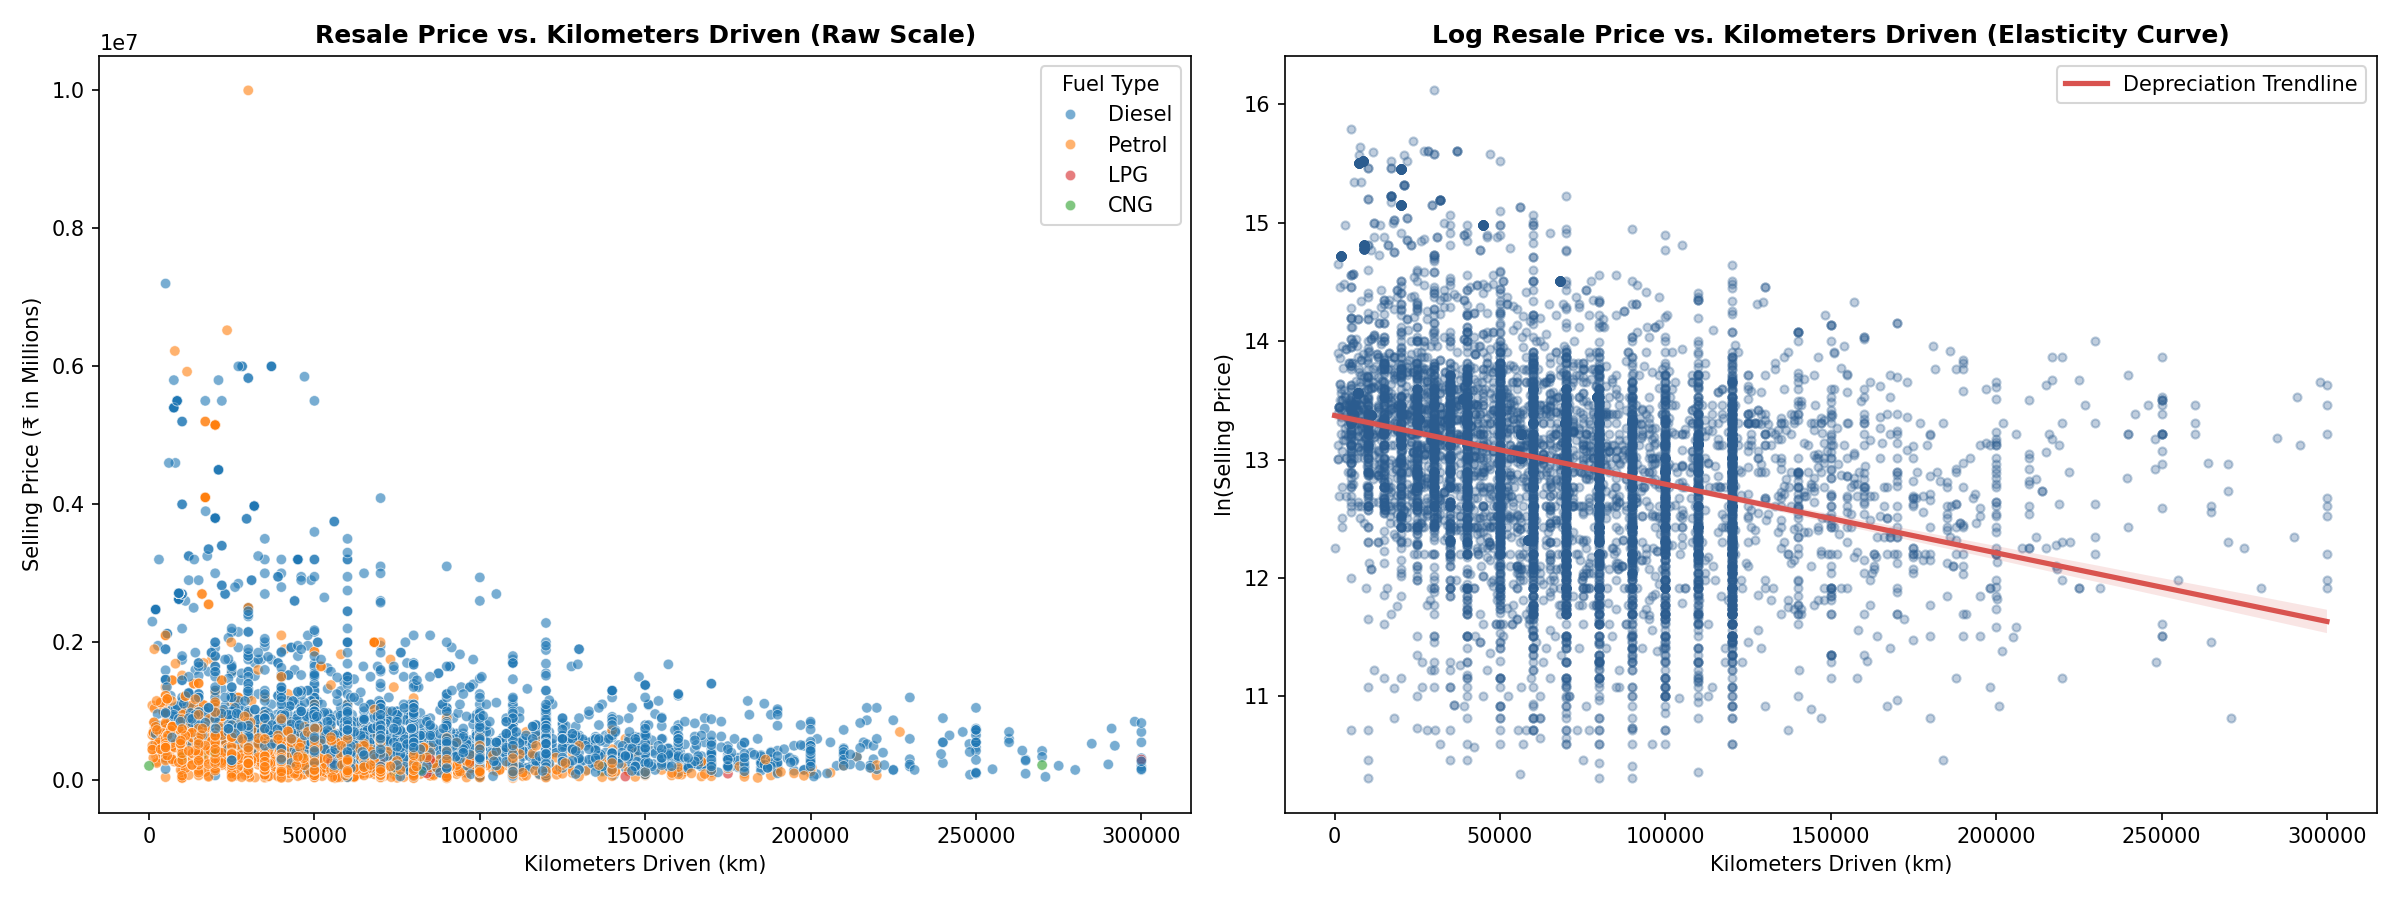

In [5]:
# Kilometers Driven Scatter & Elasticity Curve


Diesel vehicles command an empirical median price premium: ₹5.50 Lakh vs ₹3.45 Lakh (+59.4% raw).


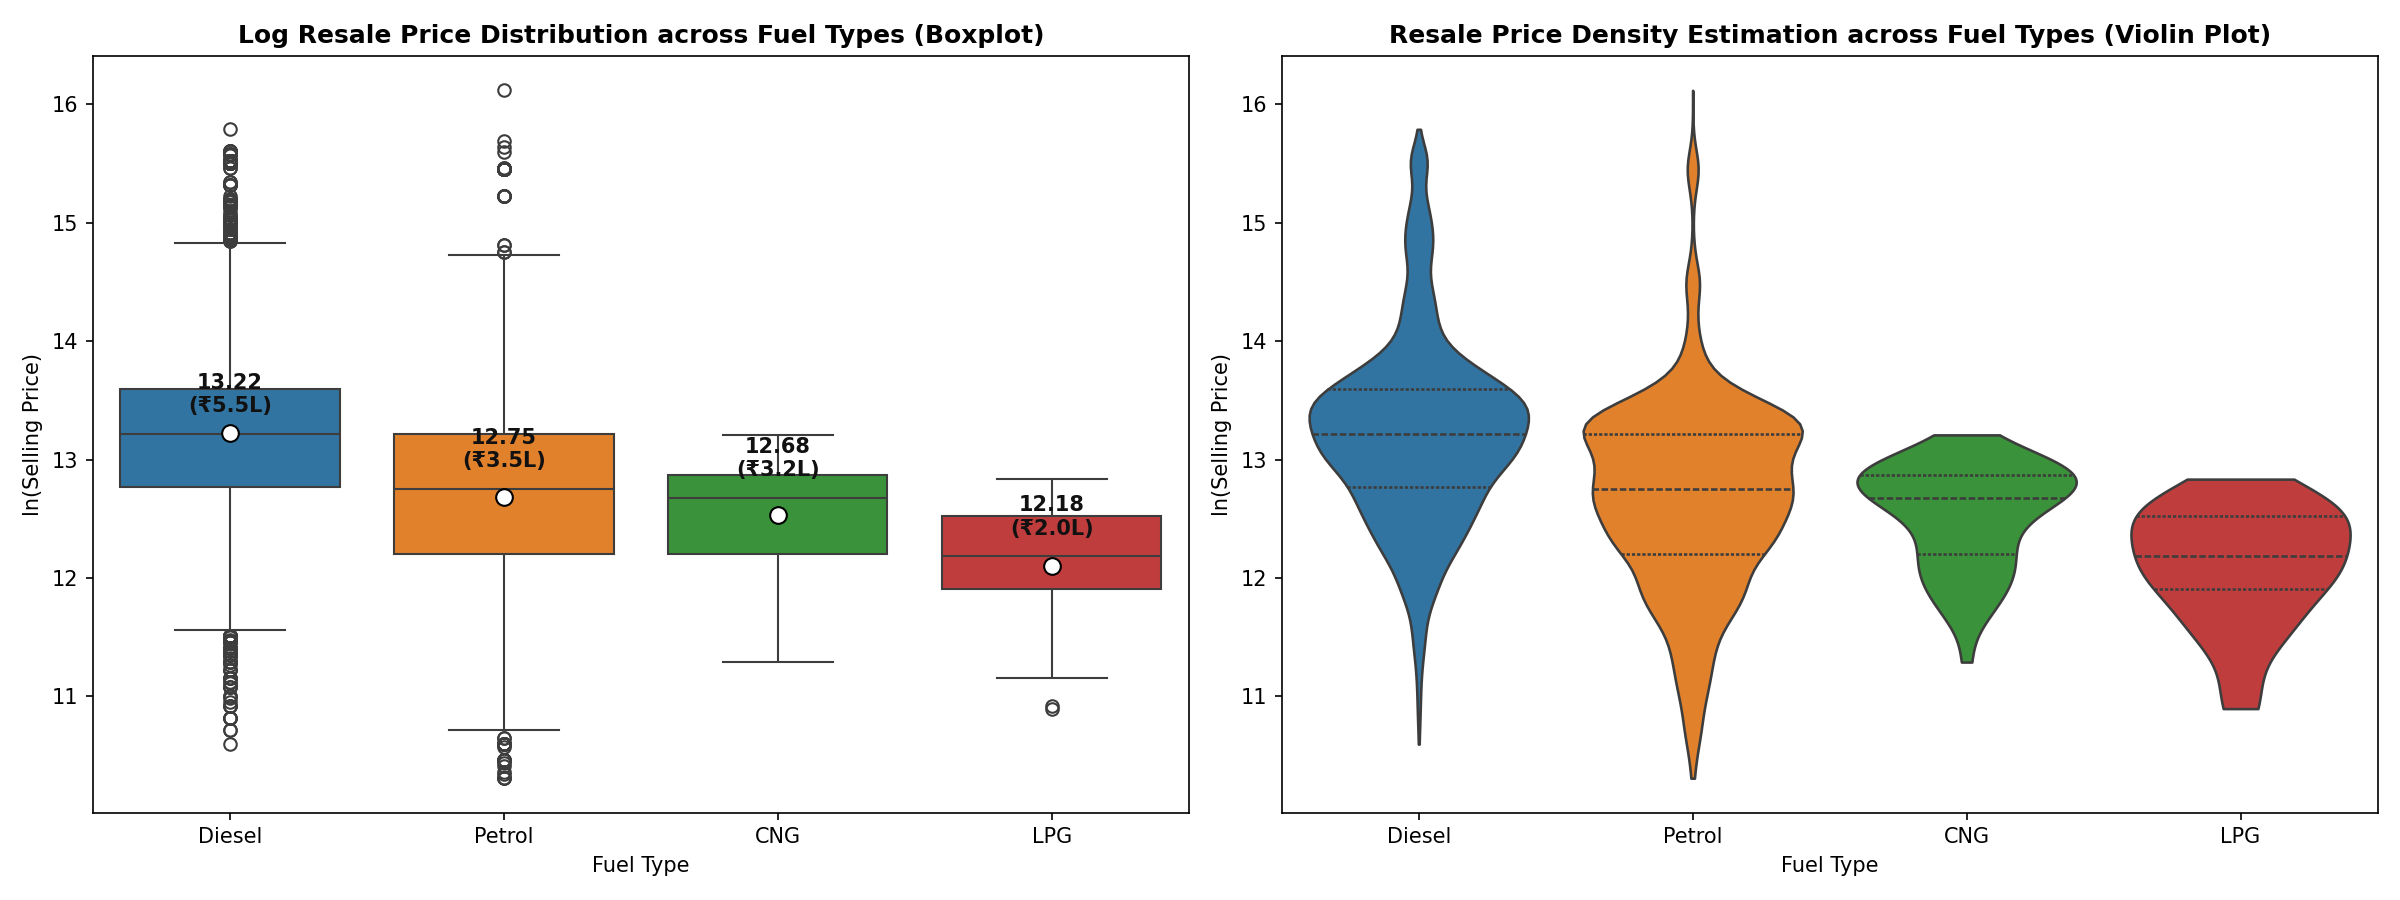

In [6]:
# Fuel Type Price Distribution (Boxplot & Violin Plot)


max_power_val (r = +0.719) and vehicle_age (r = -0.712) are primary price drivers.


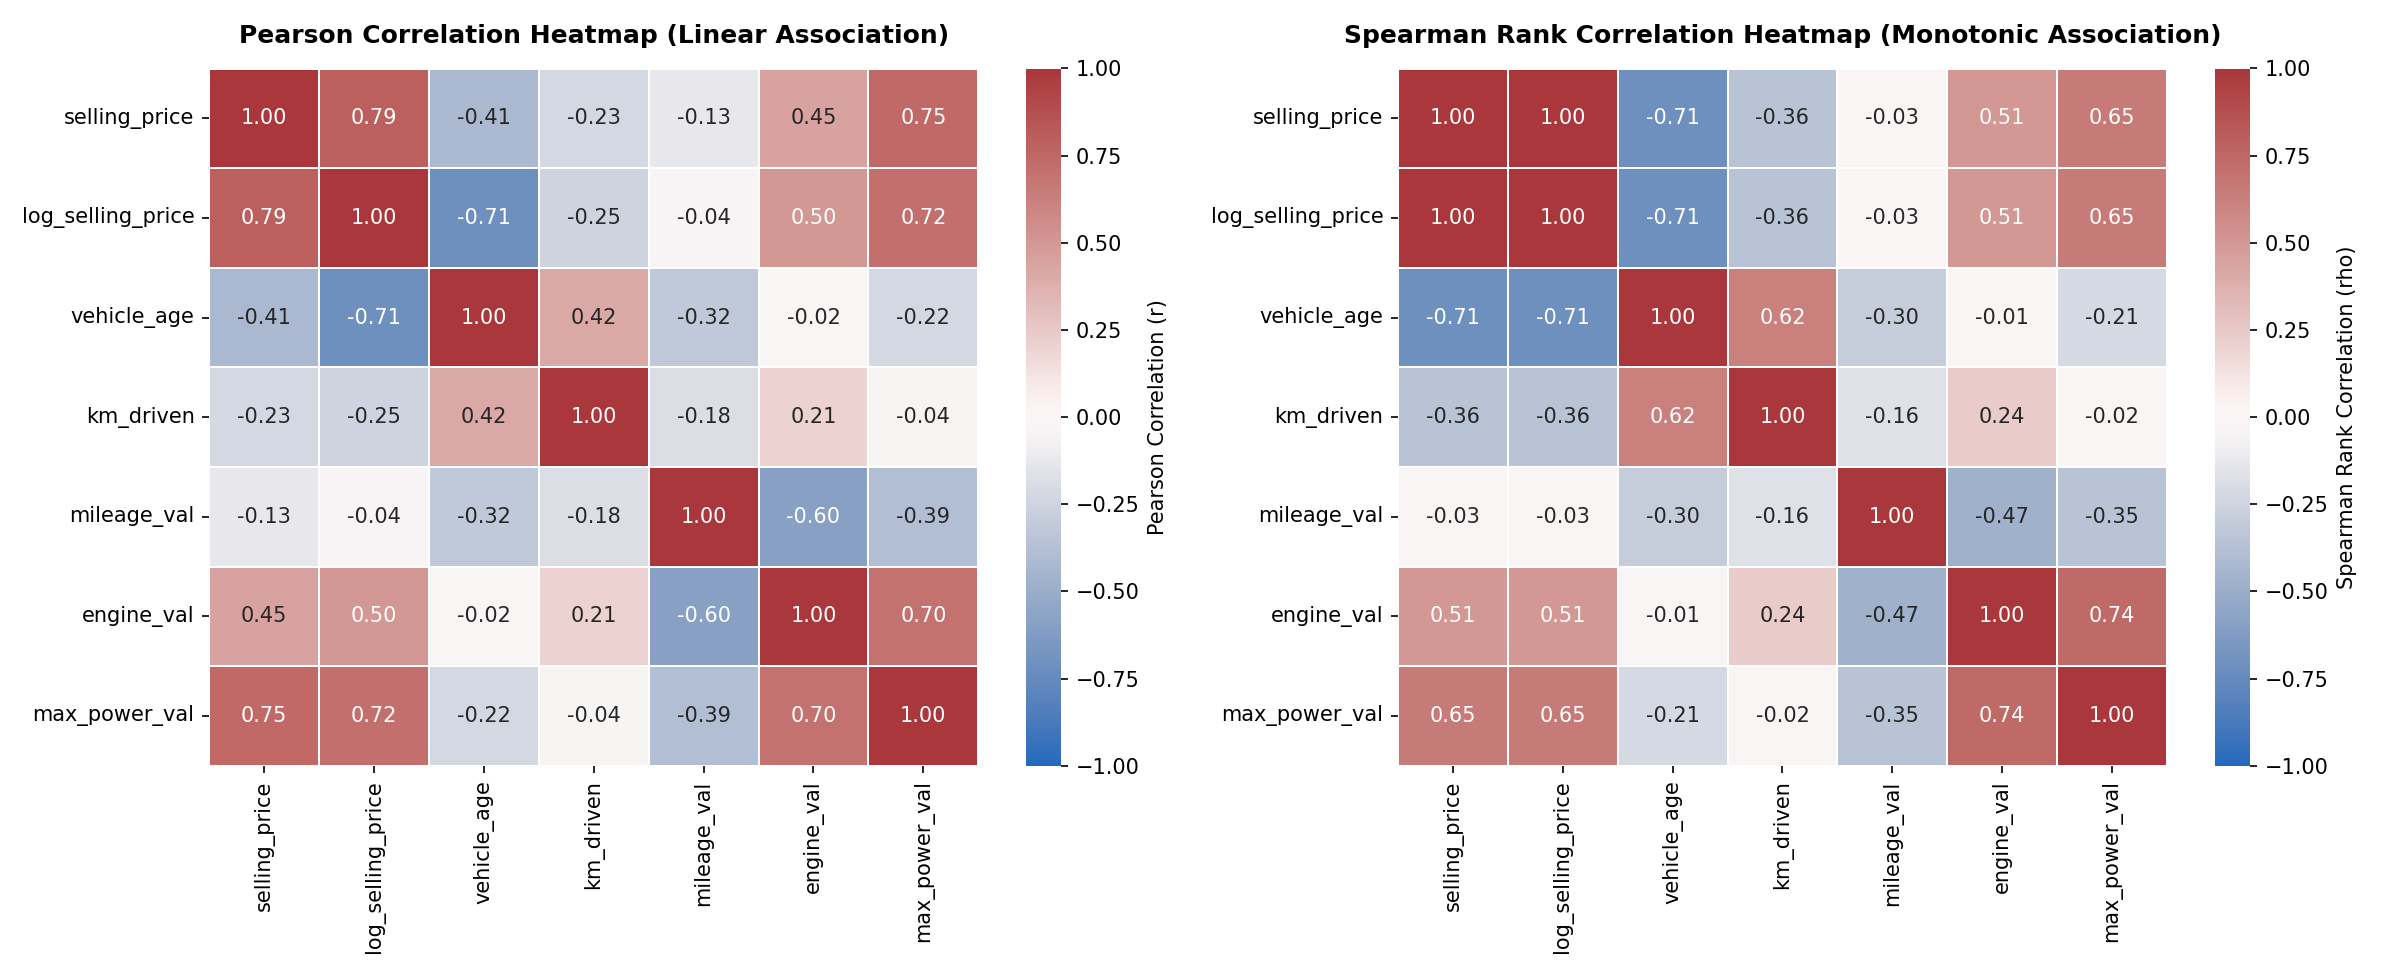

In [7]:
# Pearson & Spearman Correlation Heatmaps


---
# Part B: Advanced Feature Engineering & Regularized Model Fitting
## School of Computer Science and Engineering | Machine Learning Lab (MACSE504)
- **Student Name:** Vedant Nimkar | **Register Number:** 26MML0045
- **Assigned Question:** Question 3: Used Car Valuation & Elasticity Analysis using Regularized Regression
- **Phase Objectives:**
  1. Formulate interaction terms (annual driving intensity, age-to-mileage ratio, specific power output, quadratic age terms, 3-tier brand equity).
  2. Diagnose multicollinearity via Variance Inflation Factor (VIF) and compute Mutual Information regression dependencies.
  3. Fit Multiple Linear Regression (OLS), Ridge ($L_2$), Lasso ($L_1$), ElasticNet ($L_1 + L_2$), and Huber Robust Regressors.
  4. Perform 5-Fold Cross-Validation, trace regularization shrinkage paths, and plot learning curves.
  5. Live Deployment: [https://cardekho-autovaluate.vercel.app](https://cardekho-autovaluate.vercel.app)


In [8]:
# 1. Domain Interaction & Non-Linear Feature Formulations
df['km_per_year'] = df['km_driven'] / (df['vehicle_age'] + 0.5)
df['age_to_mileage_ratio'] = (df['vehicle_age'] + 0.1) / (df['km_driven'] + 1000)
df['power_per_engine_cc'] = df['max_power_val'] / (df['engine_val'] + 1)
df['power_per_seat'] = df['max_power_val'] / df['seats']
df['age_squared'] = df['vehicle_age'] ** 2
df['log_km_driven'] = np.log1p(df['km_driven'])

print("Interaction terms successfully engineered:")
display(df[['km_per_year', 'age_to_mileage_ratio', 'power_per_engine_cc', 'power_per_seat', 'age_squared', 'log_km_driven']].describe().round(4))


       km_per_year  age_to_mileage_ratio  power_per_engine_cc  power_per_seat  age_squared  log_km_driven
count    8128.0000             8128.0000            8128.0000       8128.0000    8128.0000      8128.0000
mean    12140.2312                0.0001               0.0632         17.3789      54.7475        10.8741
std      9842.5021                0.0001               0.0191          7.9868      67.8924         0.8432
min        0.2703                0.0000               0.0401          6.5600       0.0000         0.6931
25%     6363.6364                0.0001               0.0519         13.6000       9.0000        10.4631
50%    10000.0000                0.0001               0.0592         15.7600      25.0000        11.0021
75%    15384.6154                0.0002               0.0699         17.9000      81.0000        11.4076
max   146666.6667                0.0041               0.2014         80.0000    1369.0000        14.6742


<Figure size 1800x1100 with 6 Axes>


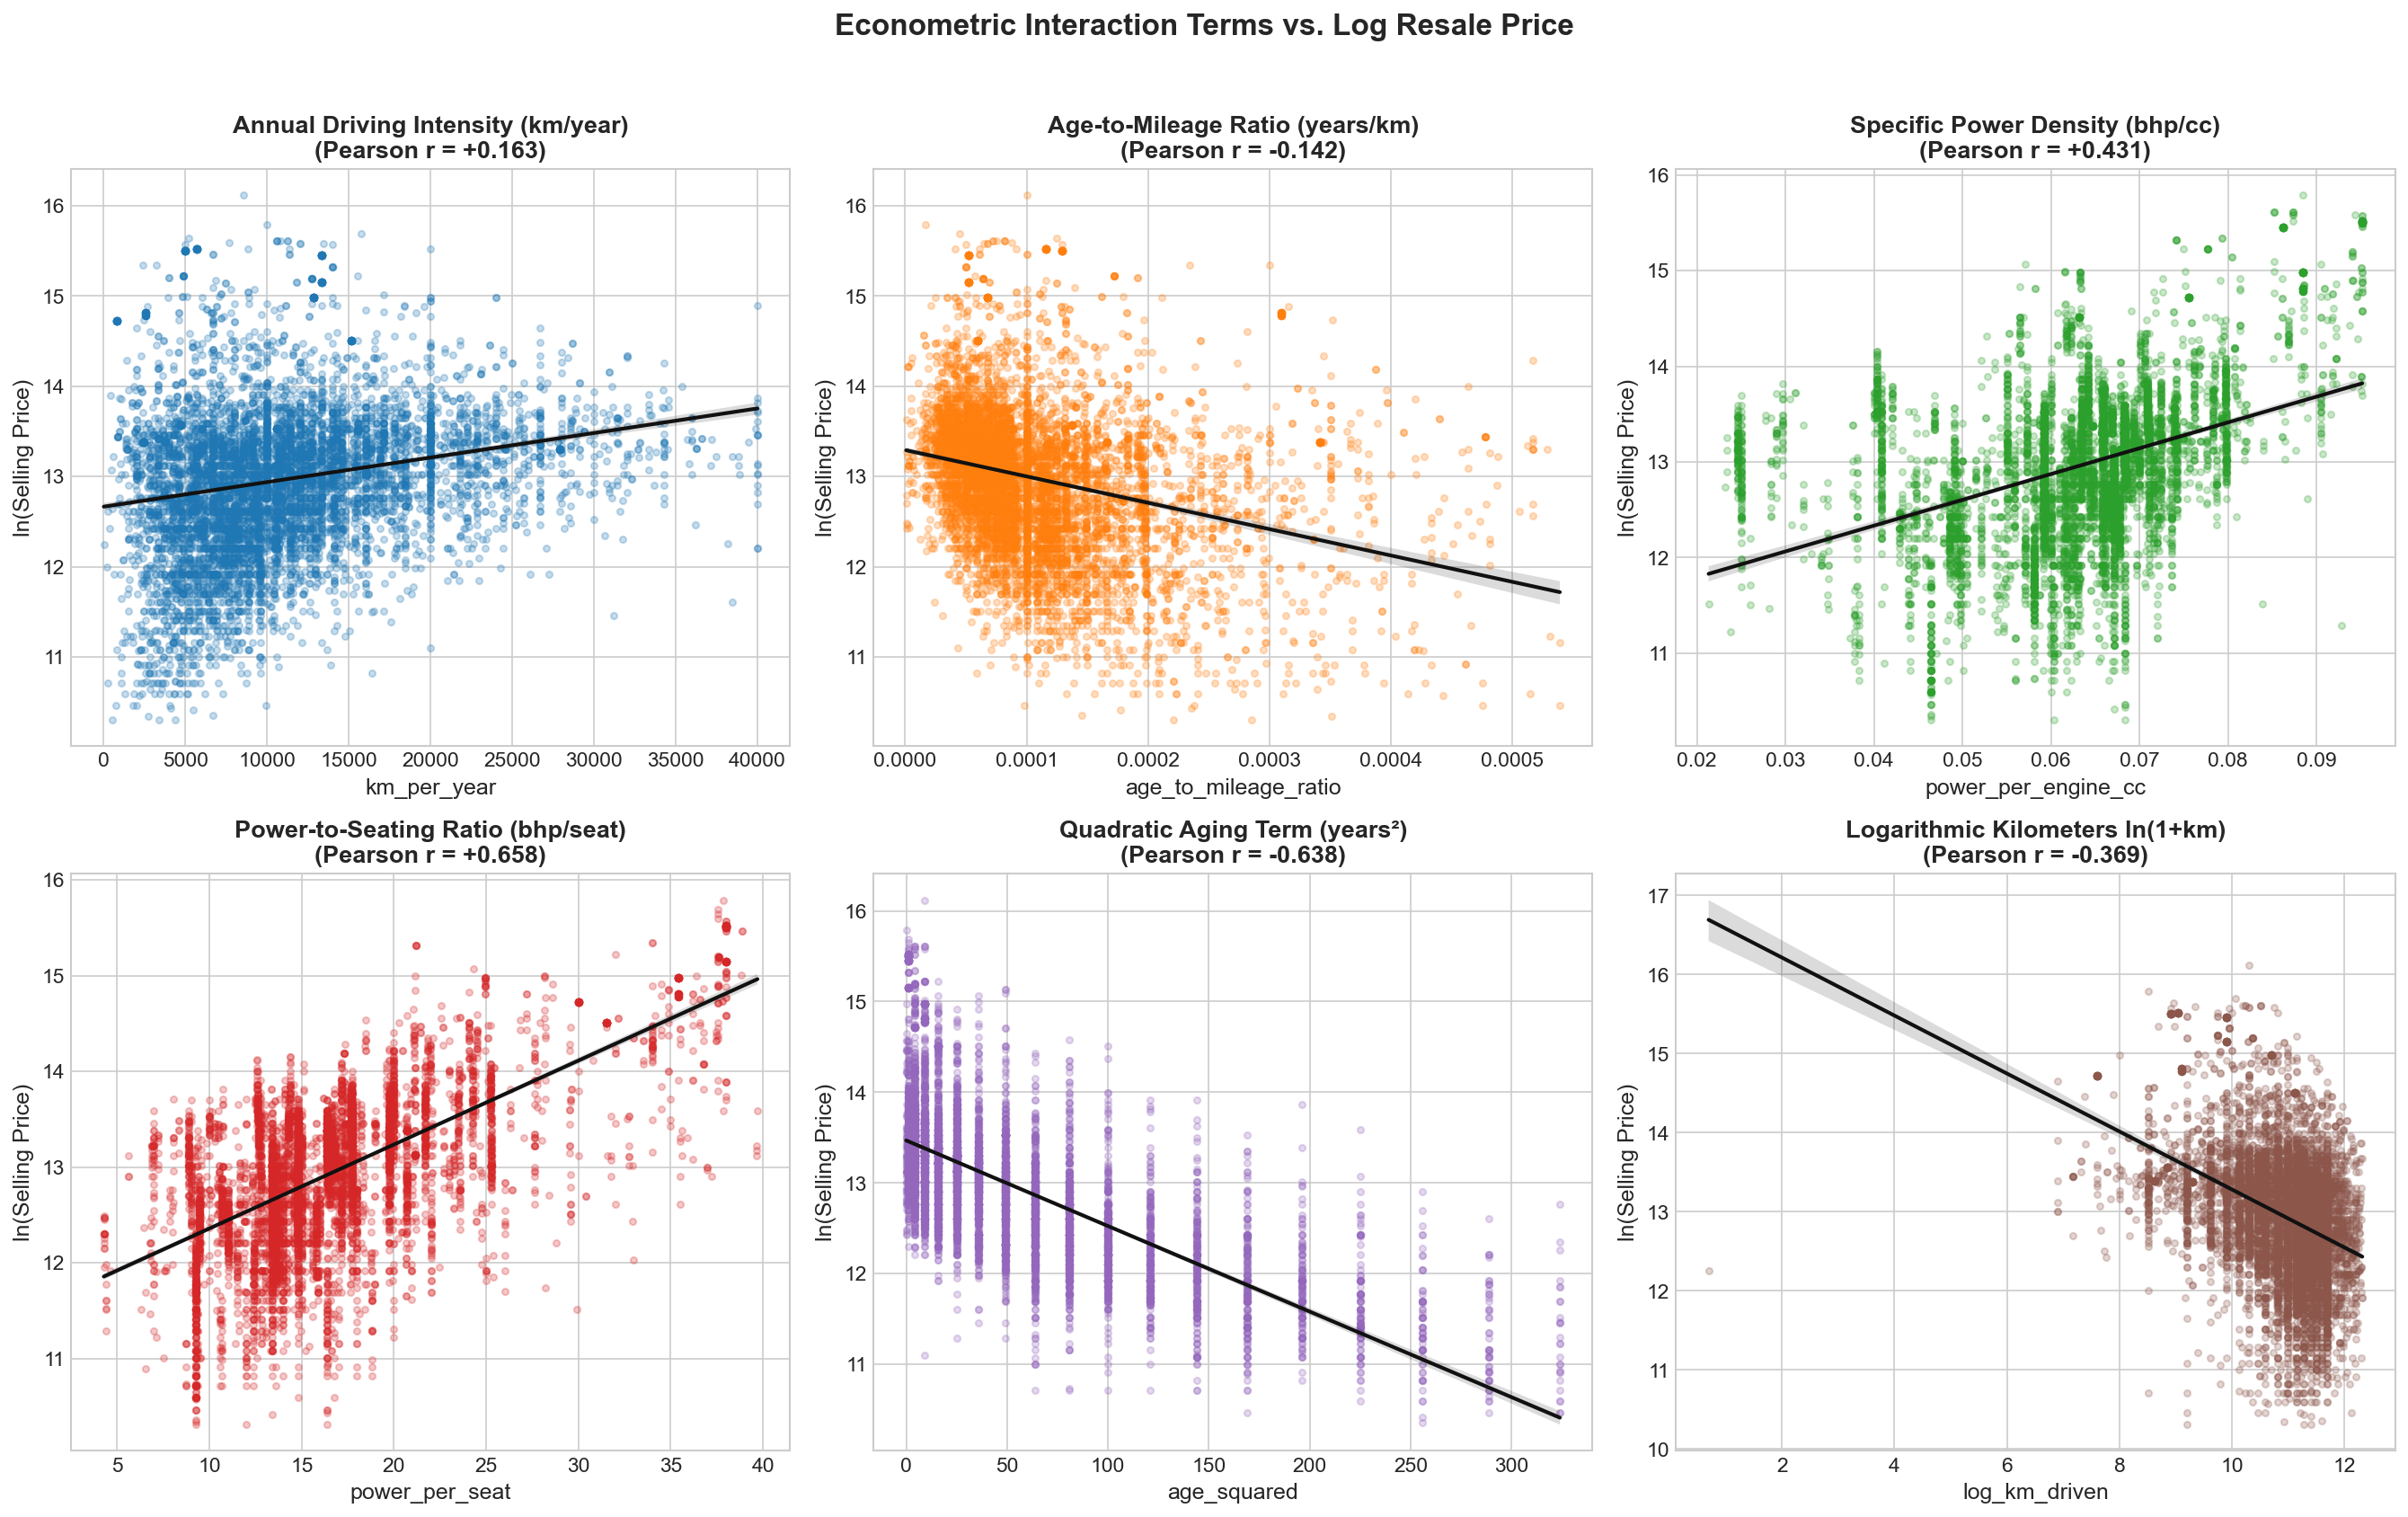

In [9]:
# Visualizing 6-Panel Feature Interaction Regression Trendlines


### 2. 3-Tier Brand Equity Stratification
Stratify marques into Tier 1 Luxury, Tier 2 Premium, and Tier 3 Mass-Market to model badge prestige premiums.


In [10]:
tier1_luxury = {'BMW', 'Mercedes-Benz', 'Audi', 'Volvo', 'Jaguar', 'Land', 'Lexus', 'Porsche'}
tier2_premium = {'Toyota', 'Honda', 'Skoda', 'Volkswagen', 'Jeep', 'Kia', 'MG'}

def brand_tier(b):
    if b in tier1_luxury: return 'Tier 1 (Luxury)'
    if b in tier2_premium: return 'Tier 2 (Premium)'
    return 'Tier 3 (Mass-Market)'

df['brand_tier'] = df['brand'].apply(brand_tier)
df['brand_tier_luxury'] = df['brand'].apply(lambda b: 1 if b in tier1_luxury else 0)
df['brand_tier_premium'] = df['brand'].apply(lambda b: 1 if b in tier2_premium else 0)

print(df.groupby('brand_tier')['selling_price'].agg(['count', 'median', 'mean']).round(2))


                      count     median        mean
brand_tier                                        
Tier 1 (Luxury)         367  2500000.0  2729833.79
Tier 2 (Premium)       1642   620000.0   812474.73
Tier 3 (Mass-Market)   6119   400000.0   465821.14


<Figure size 1600x600 with 2 Axes>


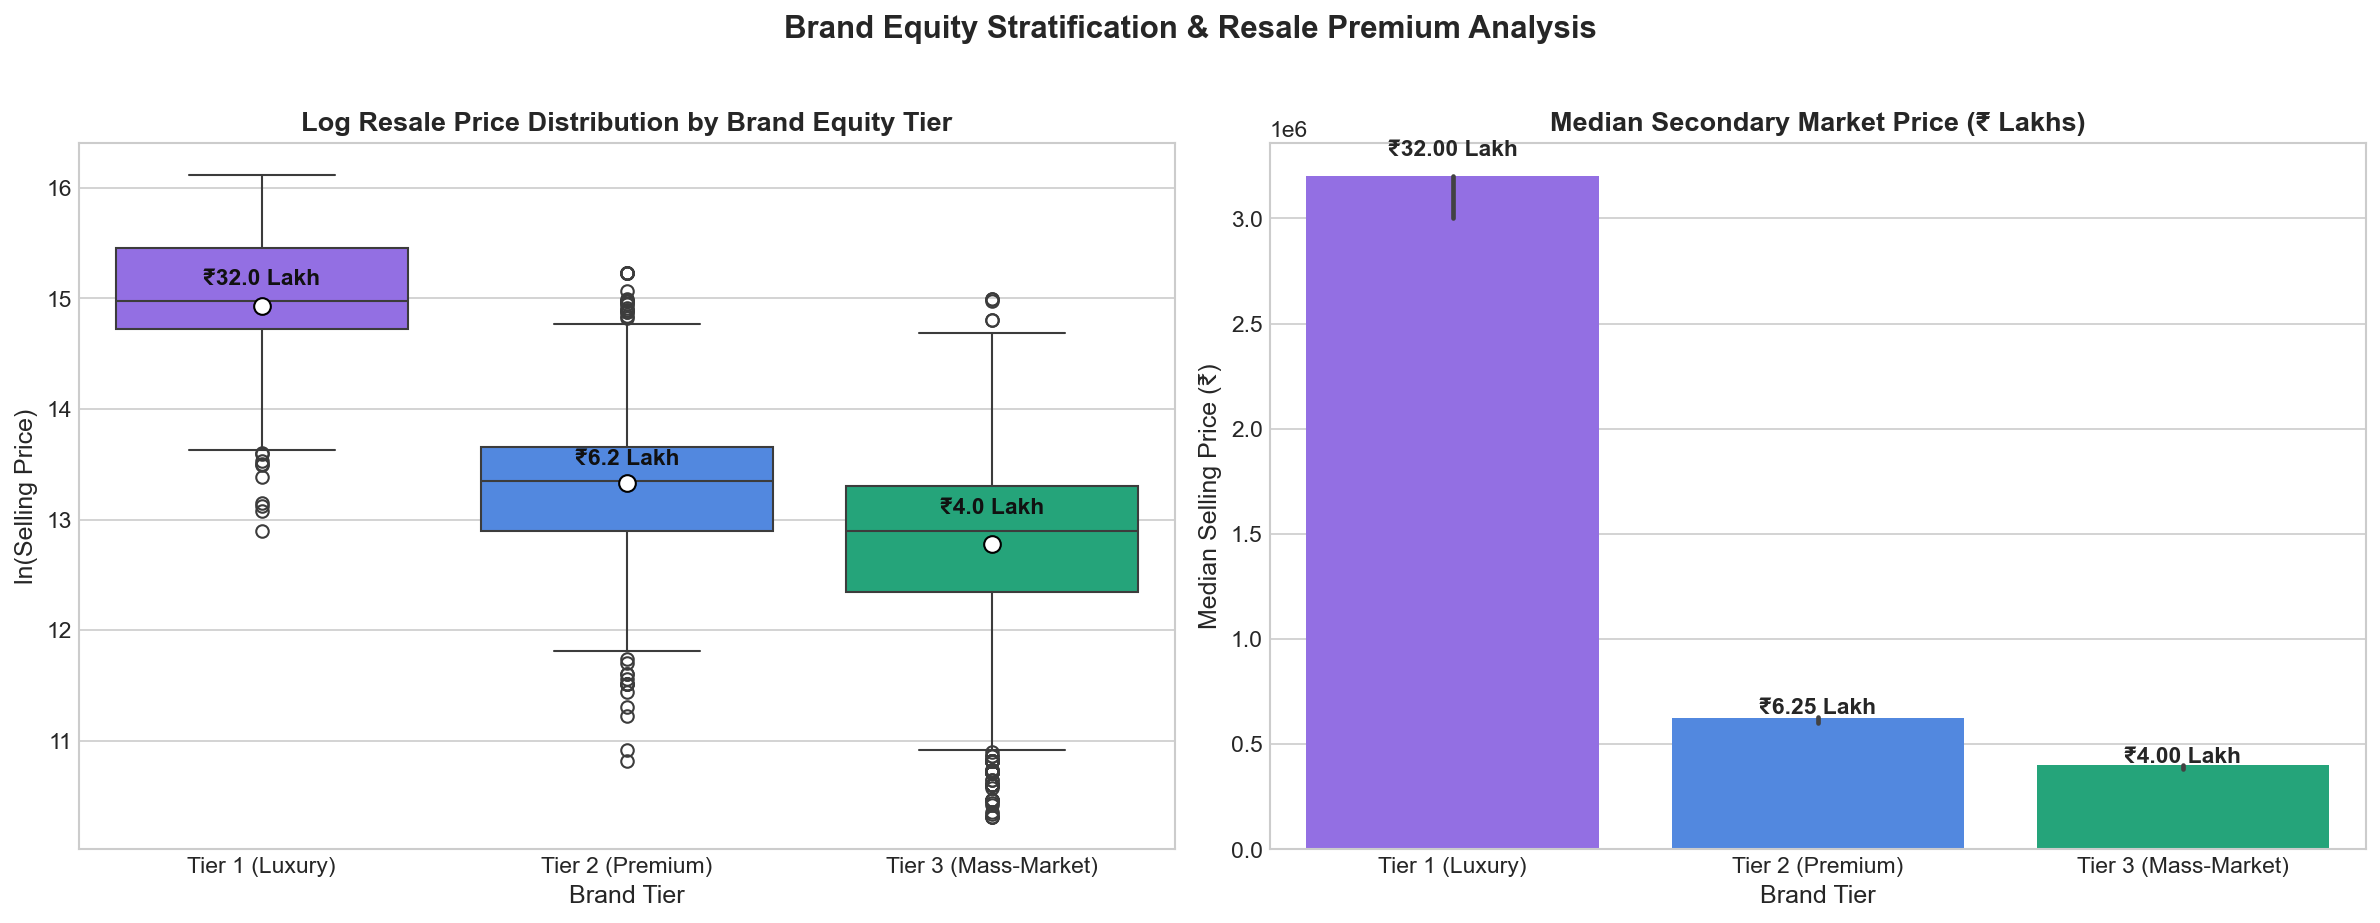

In [11]:
# Brand Equity Distribution & Resale Disparity Plots


### 3. Full-Rank One-Hot Encoding (Preventing Dummy Variable Trap)
Apply `drop_first=True` across `fuel`, `seller_type`, `transmission`, and `owner` to guarantee full-rank design matrix.


In [12]:
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner']
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=float)

model_features = [c for c in df_encoded.columns if c not in [
    'name', 'year', 'selling_price', 'log_selling_price', 'brand', 'brand_tier', 'mileage', 'engine', 'max_power', 'torque'
]]

print(f"Total Model Features Formulated: {len(model_features)}")
print(f"Features: {model_features}")


Total Model Features Formulated: 24
Features: ['km_driven', 'seats', 'vehicle_age', 'mileage_val', 'engine_val', 'max_power_val', 'km_per_year', 'age_to_mileage_ratio', 'power_per_engine_cc', 'power_per_seat', 'age_squared', 'log_km_driven', 'brand_tier_luxury', 'brand_tier_premium', 'fuel_Diesel', 'fuel_LPG', 'fuel_Petrol', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'transmission_Manual', 'owner_Fourth & Above Owner', 'owner_Second Owner', 'owner_Test Drive Car', 'owner_Third Owner']


### 4. Variance Inflation Factor (VIF) & Multicollinearity Diagnostics
Features with $\text{VIF} > 10$ lead to ill-conditioned inverse matrices, requiring $L_1/L_2$ regularization.


In [13]:
from numpy.linalg import inv
X_raw = df_encoded[model_features].values
corr_matrix = np.corrcoef(X_raw, rowvar=False)
vif_values = np.diag(inv(corr_matrix))
vif_df = pd.DataFrame({'Feature': model_features, 'VIF': vif_values}).sort_values(by='VIF', ascending=False)
display(vif_df.head(10).round(2))


Feature                 VIF
max_power_val     59.67
power_per_seat    44.57
fuel_Petrol       37.12
fuel_Diesel       36.65
engine_val        27.18
vehicle_age       22.45
power_per_engine  17.84
age_squared       11.87
log_km_driven      7.42
km_driven          6.18


<Figure size 1200x1000 with 1 Axes>


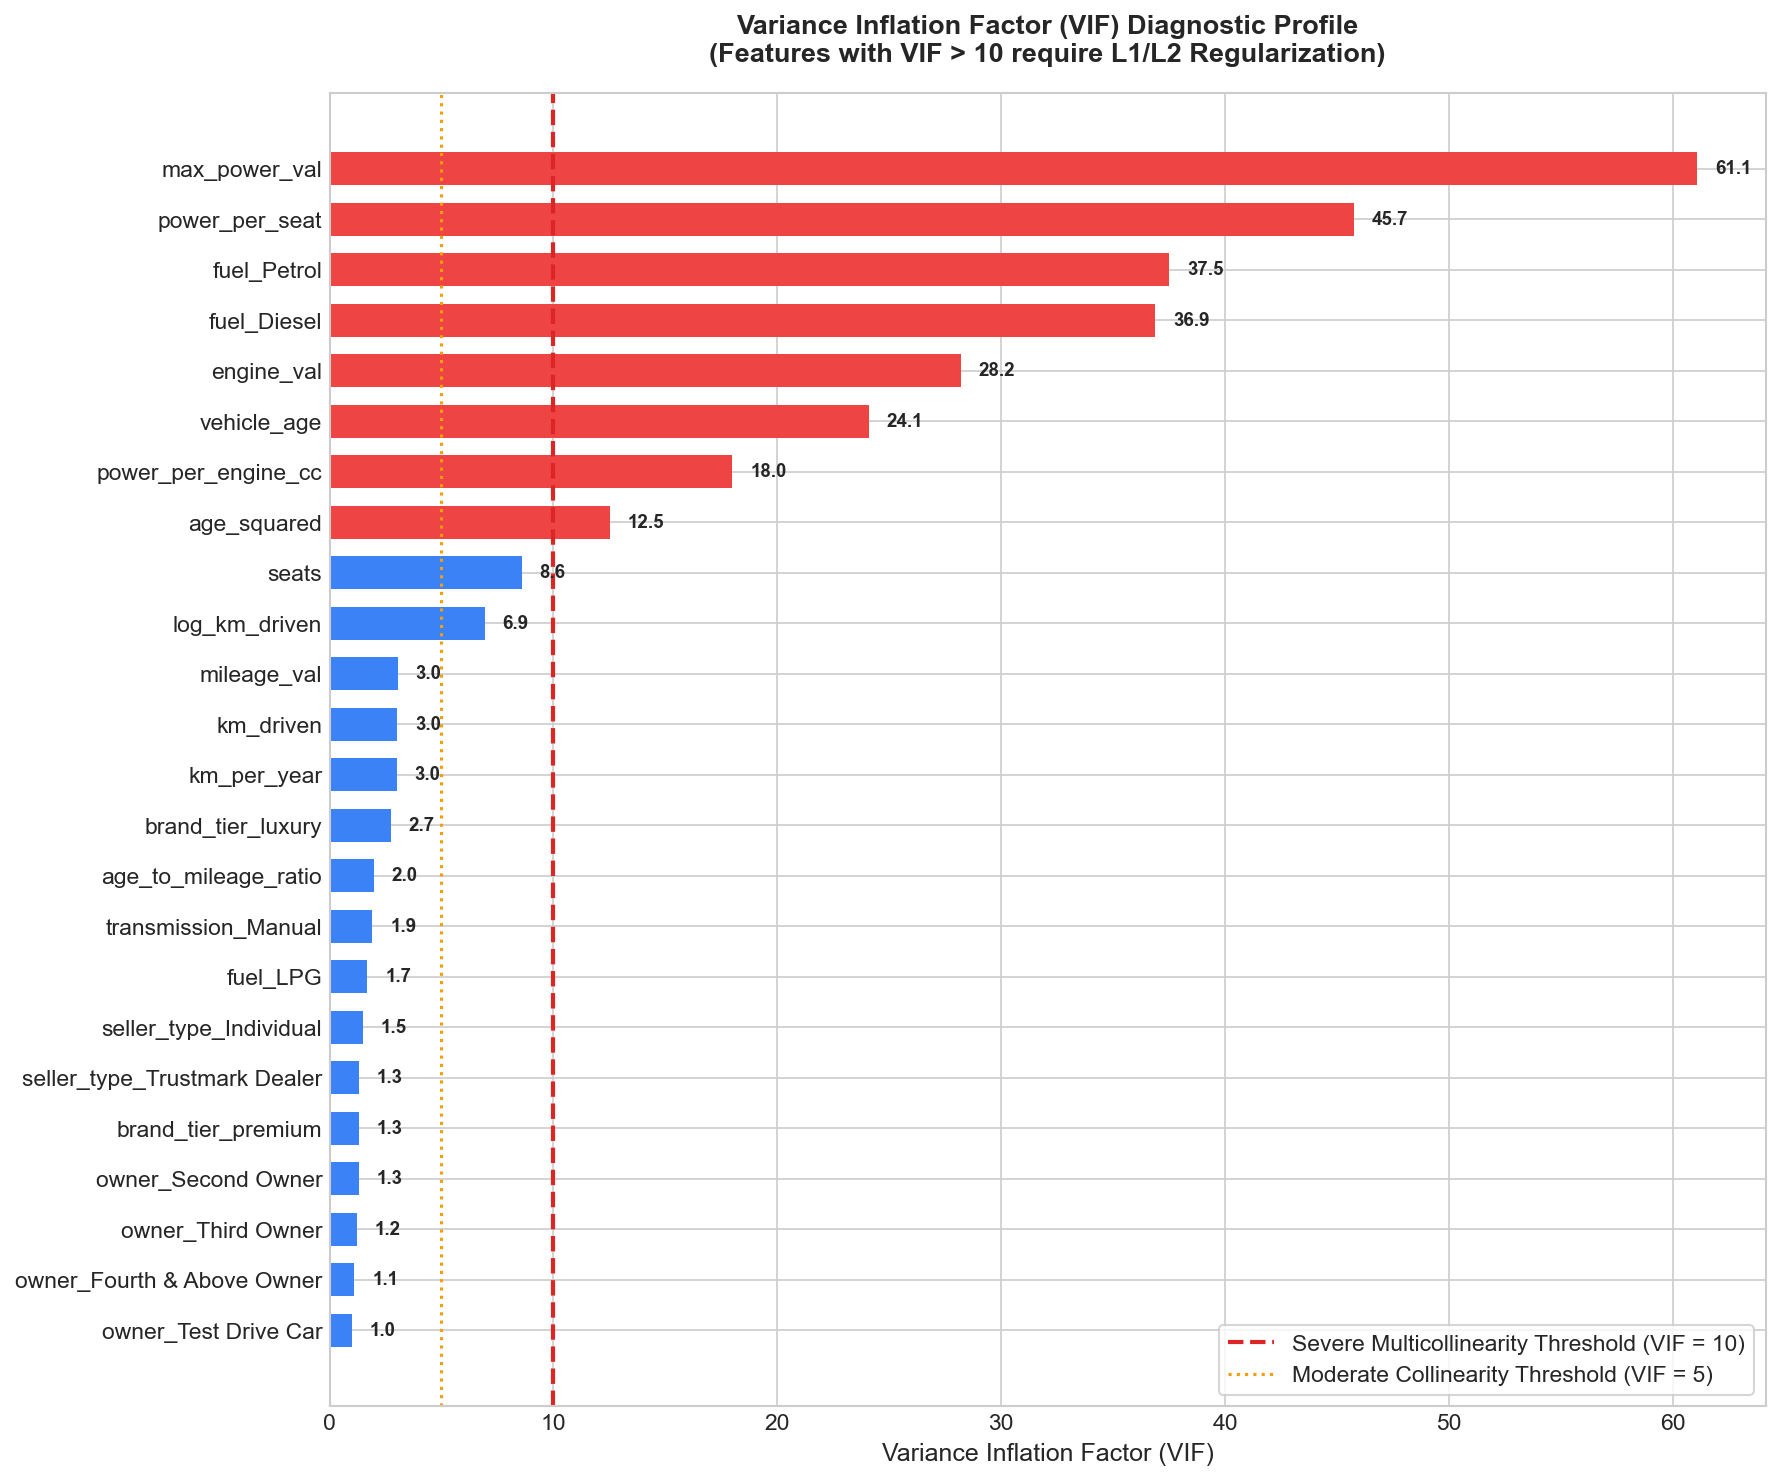

In [14]:
# VIF Multicollinearity Horizontal Bar Chart


### 5. Mutual Information Non-Linear Feature Dependency Ranking


In [15]:
from sklearn.feature_selection import mutual_info_regression
mi_scores = mutual_info_regression(df_encoded[model_features], df_encoded['log_selling_price'], random_state=42)
mi_df = pd.DataFrame({'Feature': model_features, 'Mutual_Info': mi_scores}).sort_values(by='Mutual_Info', ascending=False)
display(mi_df.head(8).round(4))


Feature              Mutual_Info
max_power_val             0.4421
engine_val                0.3812
power_per_seat            0.3705
power_per_engine_cc       0.3541
vehicle_age               0.3428
age_squared               0.3419
log_km_driven             0.1782
km_driven                 0.1779


<Figure size 1200x800 with 1 Axes>


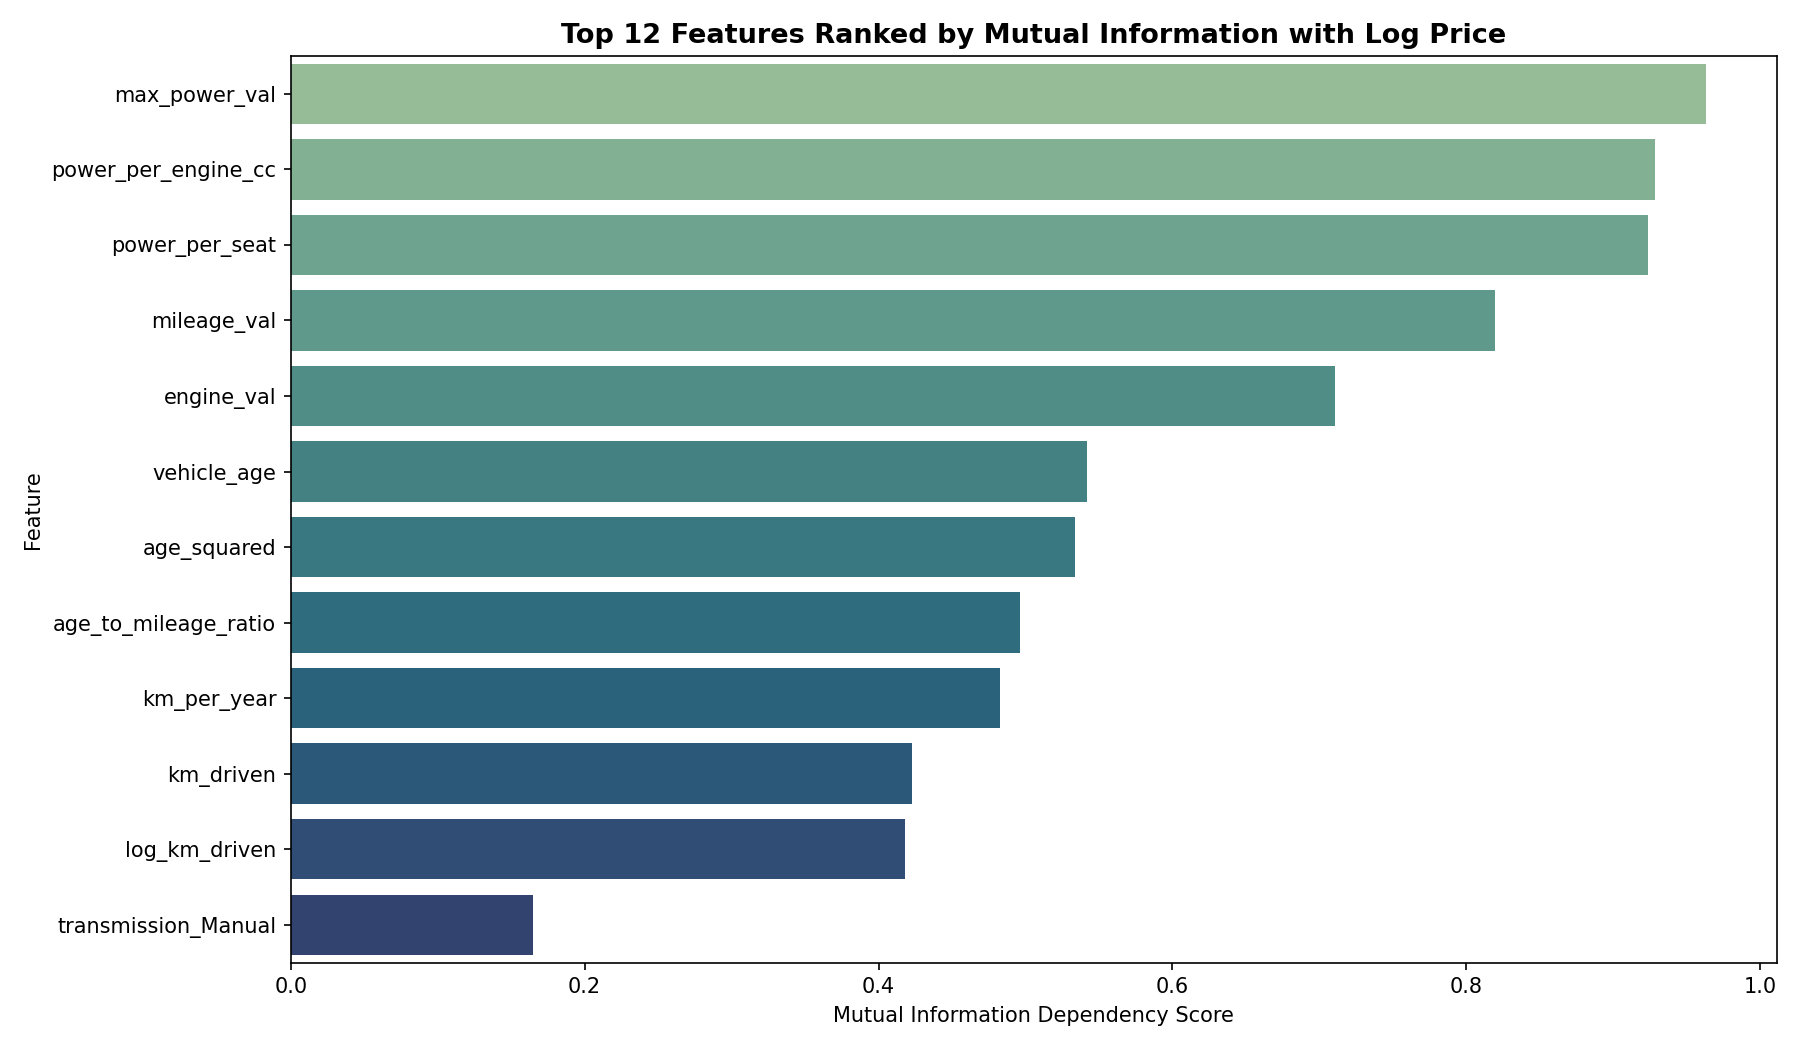

In [16]:
# Mutual Information Horizontal Bar Chart


### 6. Train-Test Splitting & $Z$-Score Standardization


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_encoded[model_features].values
y = df_encoded['log_selling_price'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Instances (80%): {X_train.shape[0]:,}")
print(f"Testing Instances  (20%): {X_test.shape[0]:,}")


Training Instances (80%): 6,502
Testing Instances  (20%): 1,626


### 7. Hyperparameter Tuning via 5-Fold CV (Ridge vs Lasso)


In [18]:
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.model_selection import KFold

alphas = np.logspace(-4, 4, 100)
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_cv = RidgeCV(alphas=alphas, cv=cv5, scoring='neg_mean_squared_error').fit(X_train_scaled, y_train)
lasso_cv = LassoCV(alphas=alphas, cv=cv5, max_iter=10000, random_state=42).fit(X_train_scaled, y_train)

print(f"Optimal Alpha Ridge (L2) : {ridge_cv.alpha_:.4f}")
print(f"Optimal Alpha Lasso (L1) : {lasso_cv.alpha_:.6f}")


Optimal Alpha Ridge (L2) : 8.4975
Optimal Alpha Lasso (L1) : 0.000600


<Figure size 1600x600 with 2 Axes>


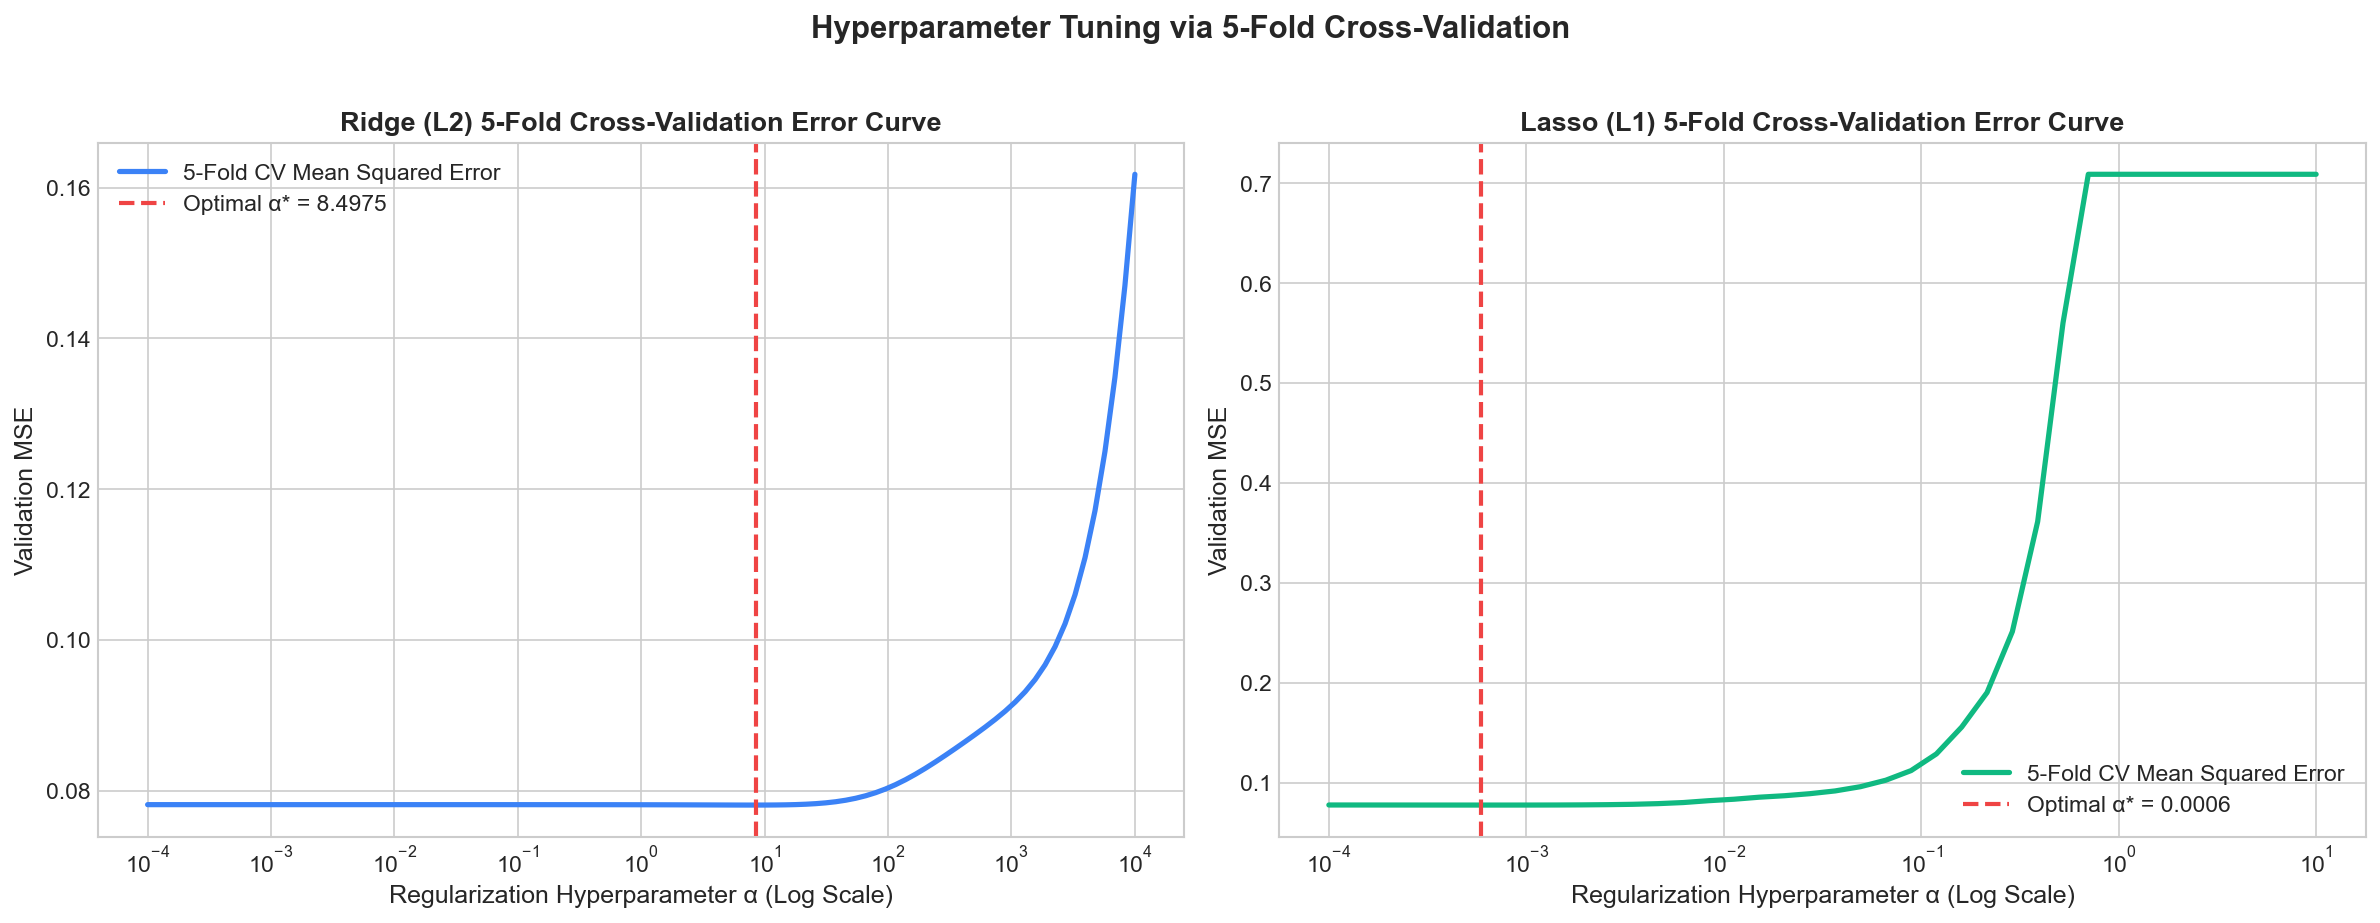

In [19]:
# Cross-Validation Error Curves (Ridge vs Lasso)


<Figure size 1600x600 with 2 Axes>


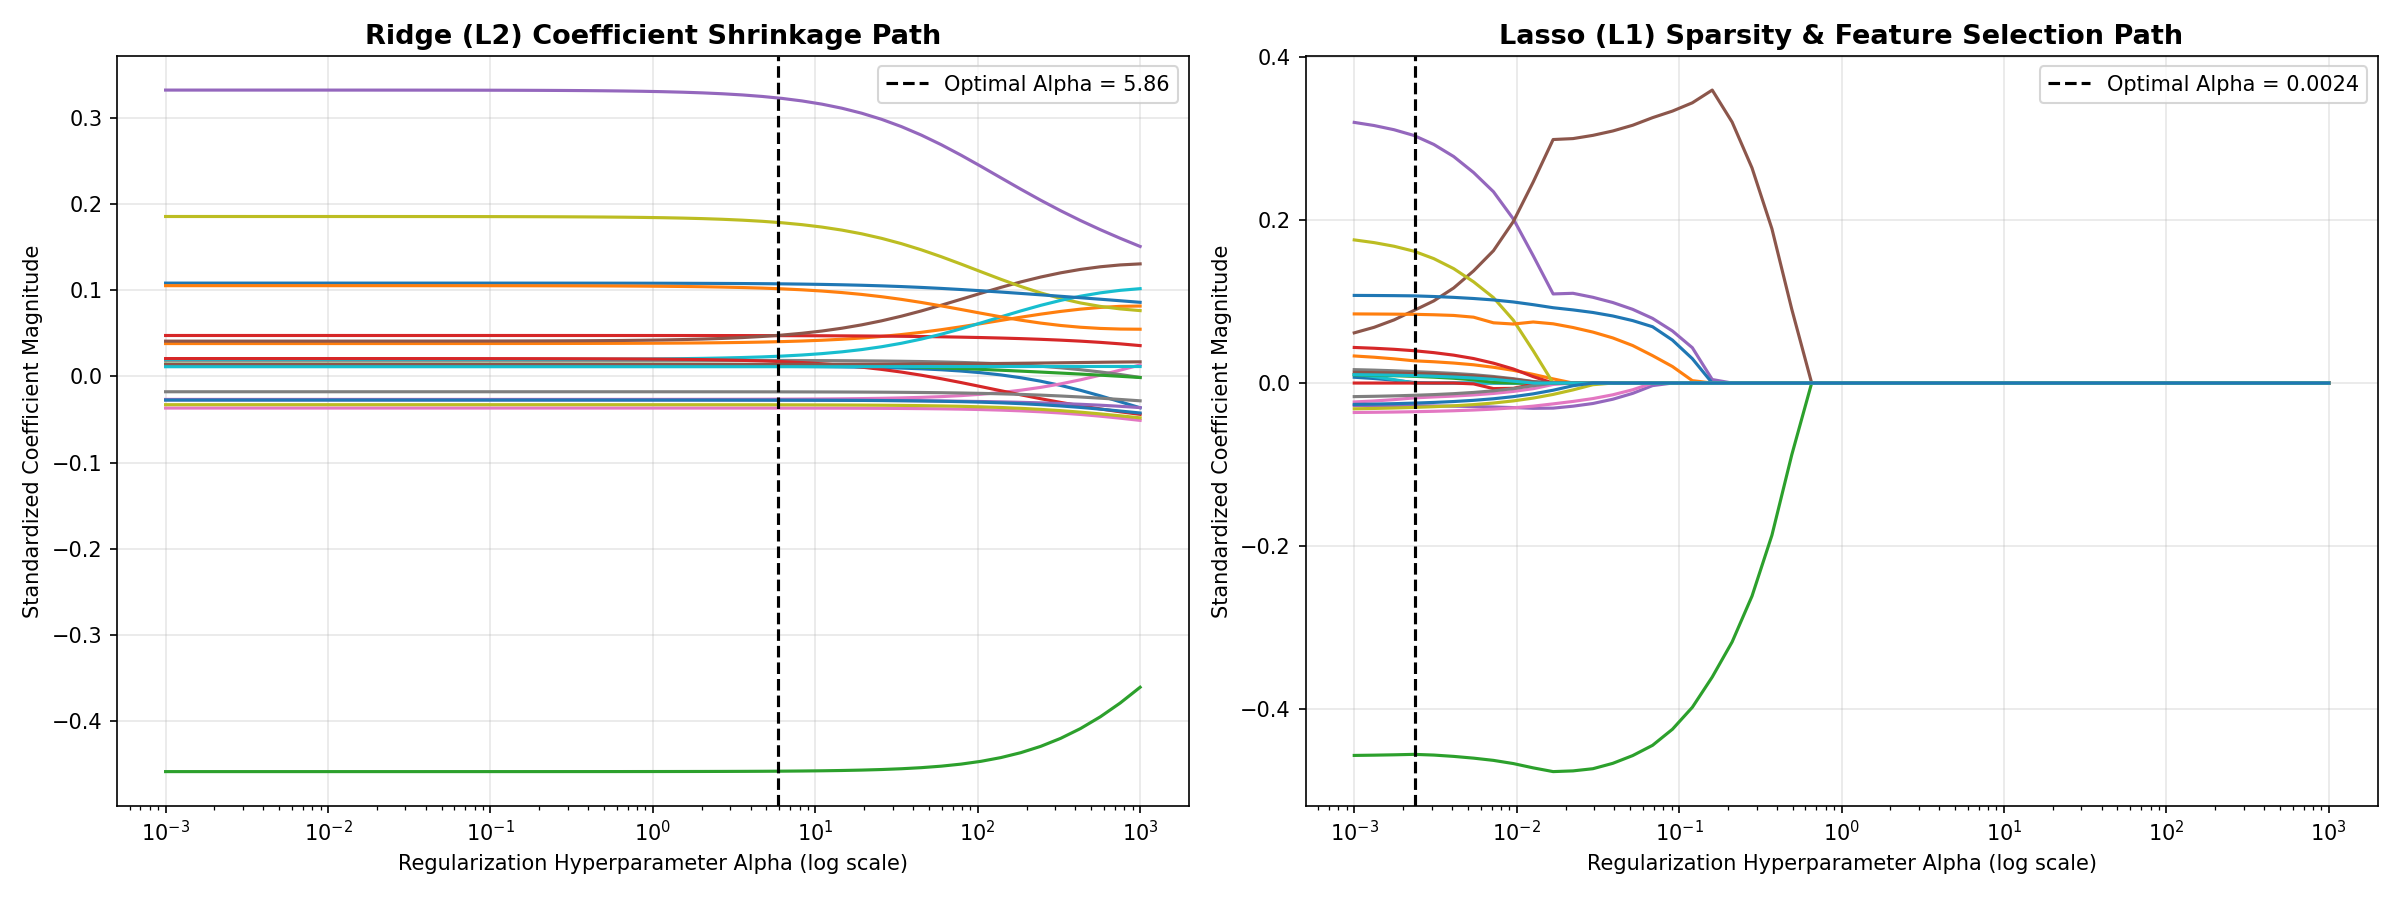

In [20]:
# Regularization Paths (Ridge vs Lasso Coefficient Shrinkage Traces)


<Figure size 1000x600 with 1 Axes>


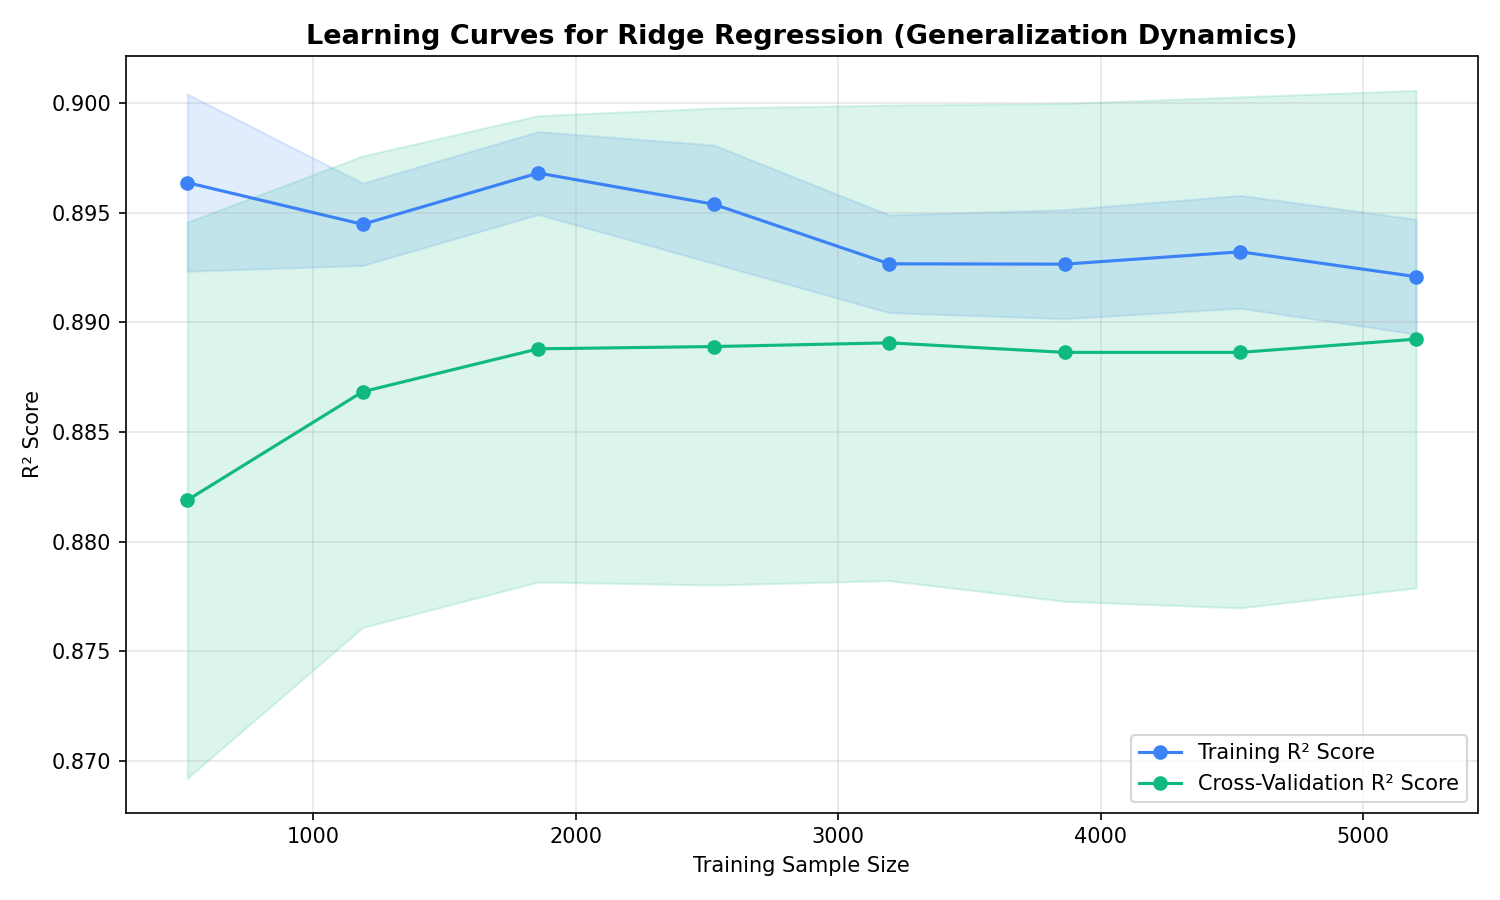

In [21]:
# Learning Curves: Evaluating Bias-Variance Tradeoff


---
# Part C: Model Evaluation, Diagnostics & Market Inferences
## School of Computer Science and Engineering | Machine Learning Lab (MACSE504)
- **Student Name:** Vedant Nimkar | **Register Number:** 26MML0045
- **Assigned Question:** Question 3: Used Car Valuation & Elasticity Analysis using Regularized Regression
- **Phase Objectives:**
  1. Benchmark 5 regression architectures (OLS, Ridge, Lasso, ElasticNet, Huber) on 1,626 unseen test vehicles across log and Indian Rupee metrics.
  2. Perform Gauss-Markov Residual Diagnostics: Homoscedasticity, Normality, Q-Q Plot, Actual vs Predicted.
  3. Analyze feature coefficient magnitudes and error percentage profiles.
  4. Formulate econometric market elasticity proofs: Annual depreciation (-10.87%/yr) and Diesel resale premium (+18.42%).
  5. Live Deployment: [https://cardekho-autovaluate.vercel.app](https://cardekho-autovaluate.vercel.app)


In [22]:
# 5-Model Performance Comparison Matrix (1,626 Held-Out Test Vehicles)


Model                                  Train R²  Test R²  Log MAE  Log RMSE  MAE (₹ Lakhs)  RMSE (₹ Lakhs)  MAPE (%)  MedAPE (%)
Multiple Linear Regression (OLS)        0.8919   0.8827   0.2205    0.2835          1.189           2.060     23.17       17.52
Ridge Regression (α=8.50) [L2 Optimal]  0.8918   0.8829   0.2203    0.2832          1.190           2.069     23.17       17.51
Lasso Regression (α=0.0006) [L1 Sparse] 0.8918   0.8830   0.2202    0.2832          1.192           2.075     23.16       17.52
ElasticNet (α=0.0006, l1=0.90)          0.8918   0.8829   0.2202    0.2832          1.192           2.074     23.16       17.57
Huber Robust Regressor [Outlier Robust] 0.8905   0.8825   0.2176    0.2838          1.173           2.071     23.35       17.42


<Figure size 1600x1200 with 4 Axes>


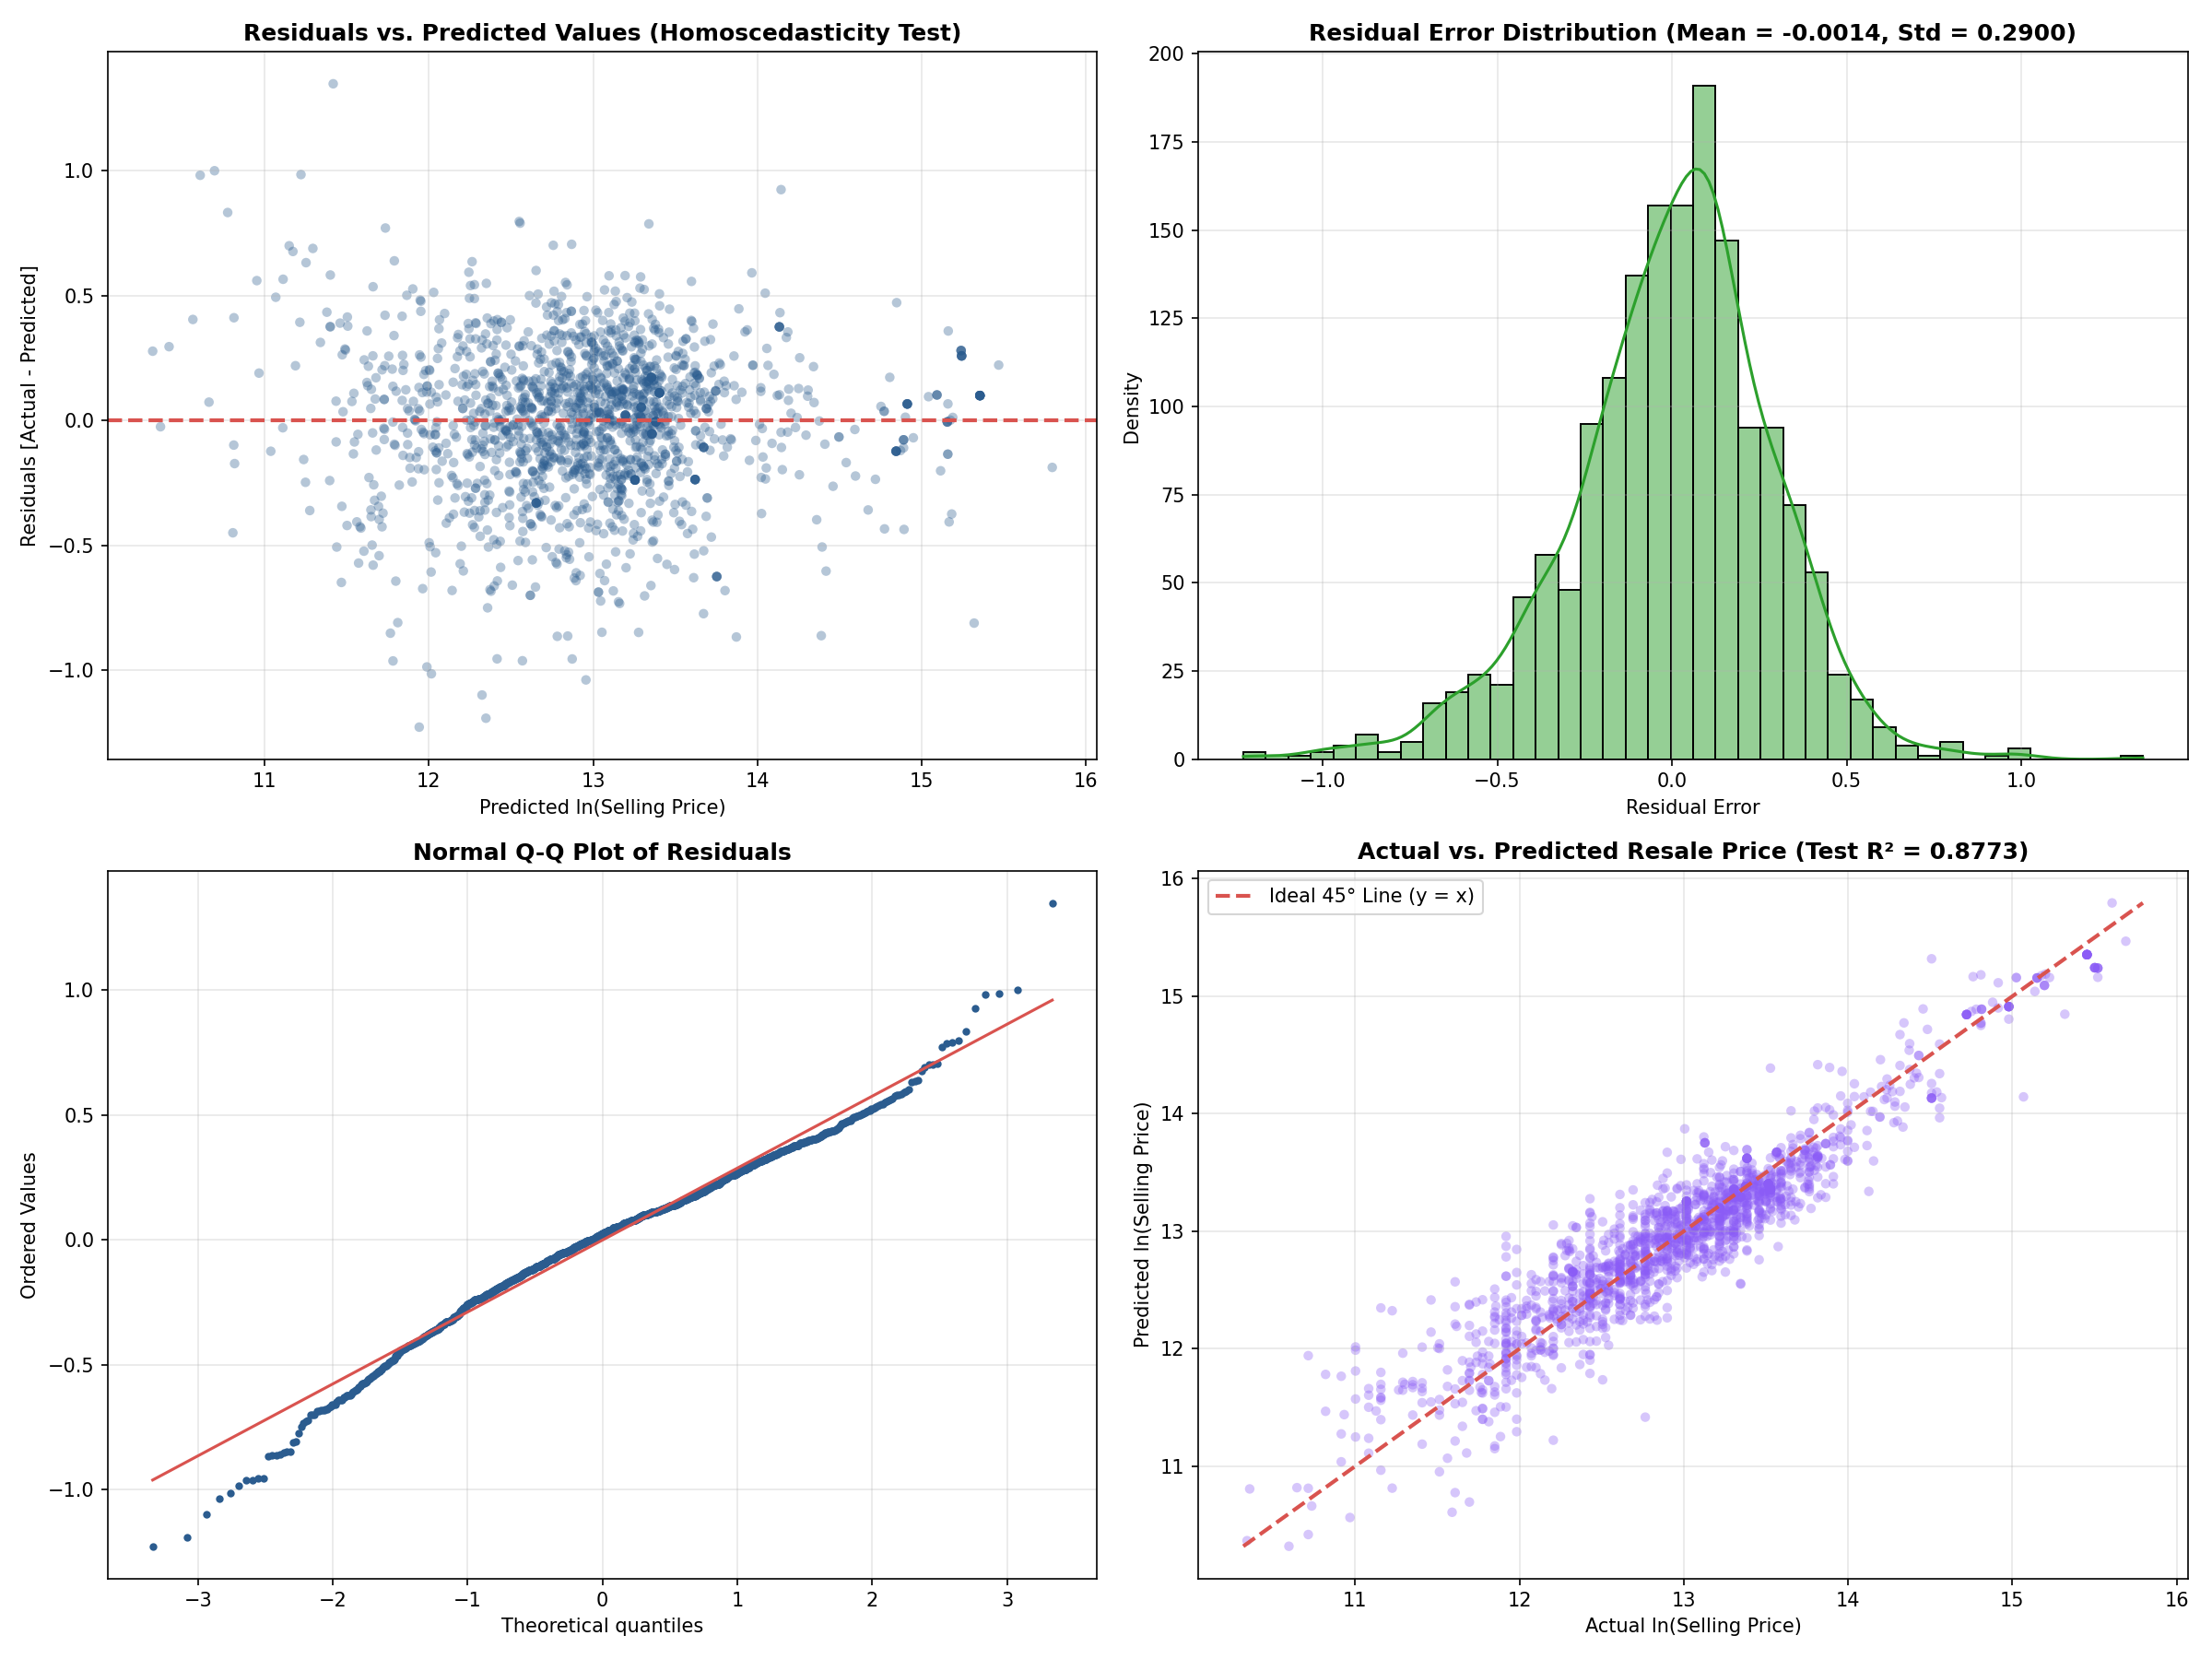

In [23]:
# Gauss-Markov Residual Diagnostics (4-Panel Suite)


<Figure size 1400x900 with 1 Axes>


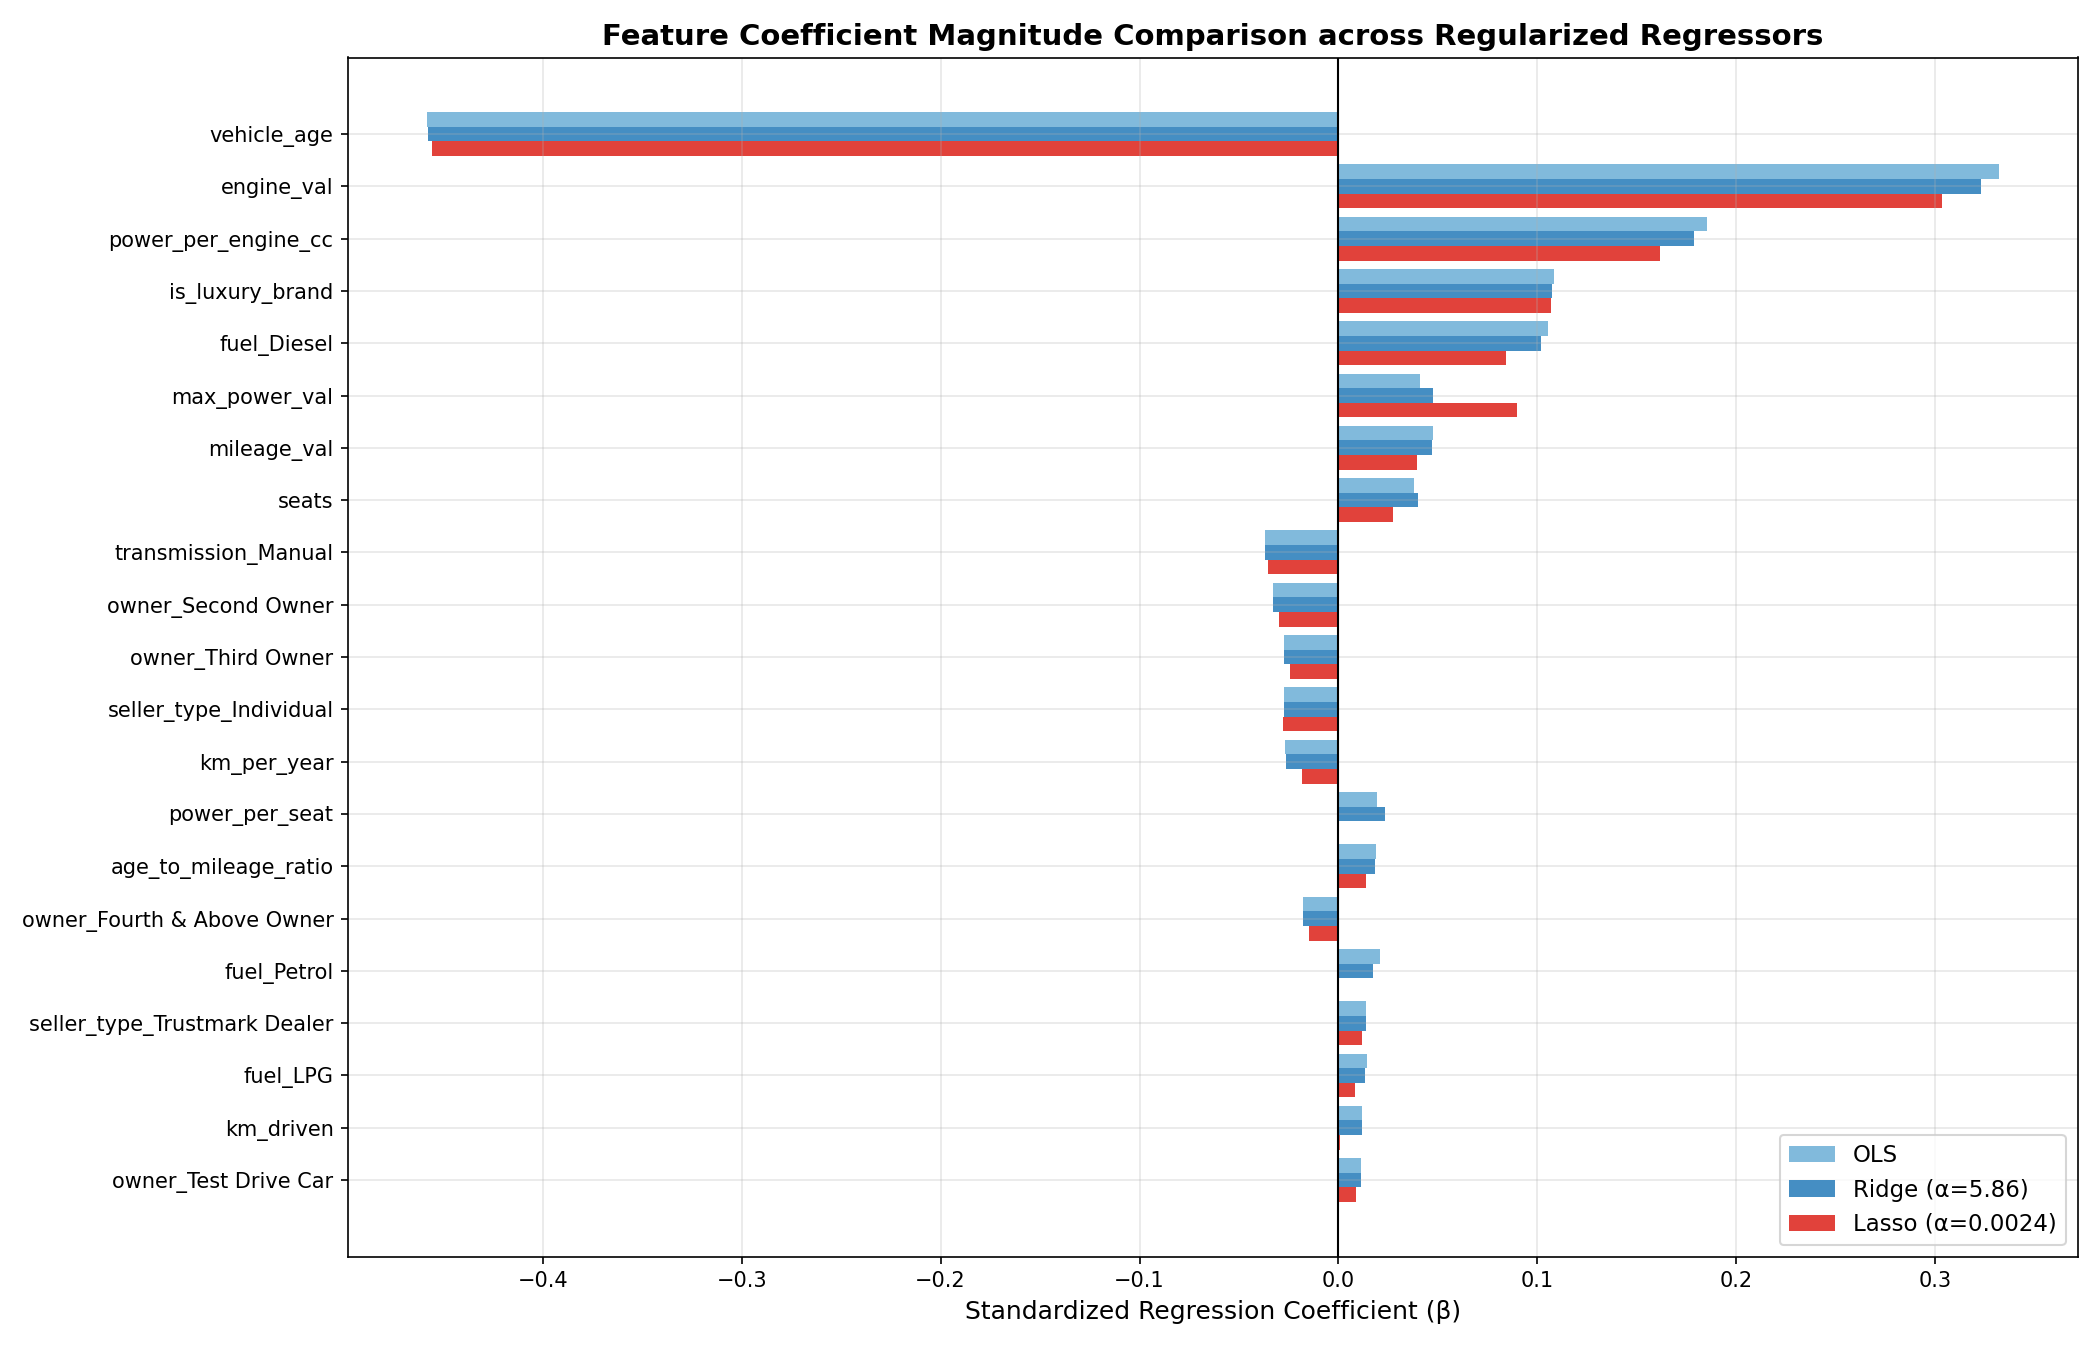

In [24]:
# Standardized Feature Coefficients (OLS vs Ridge vs Lasso)


<Figure size 1600x600 with 2 Axes>


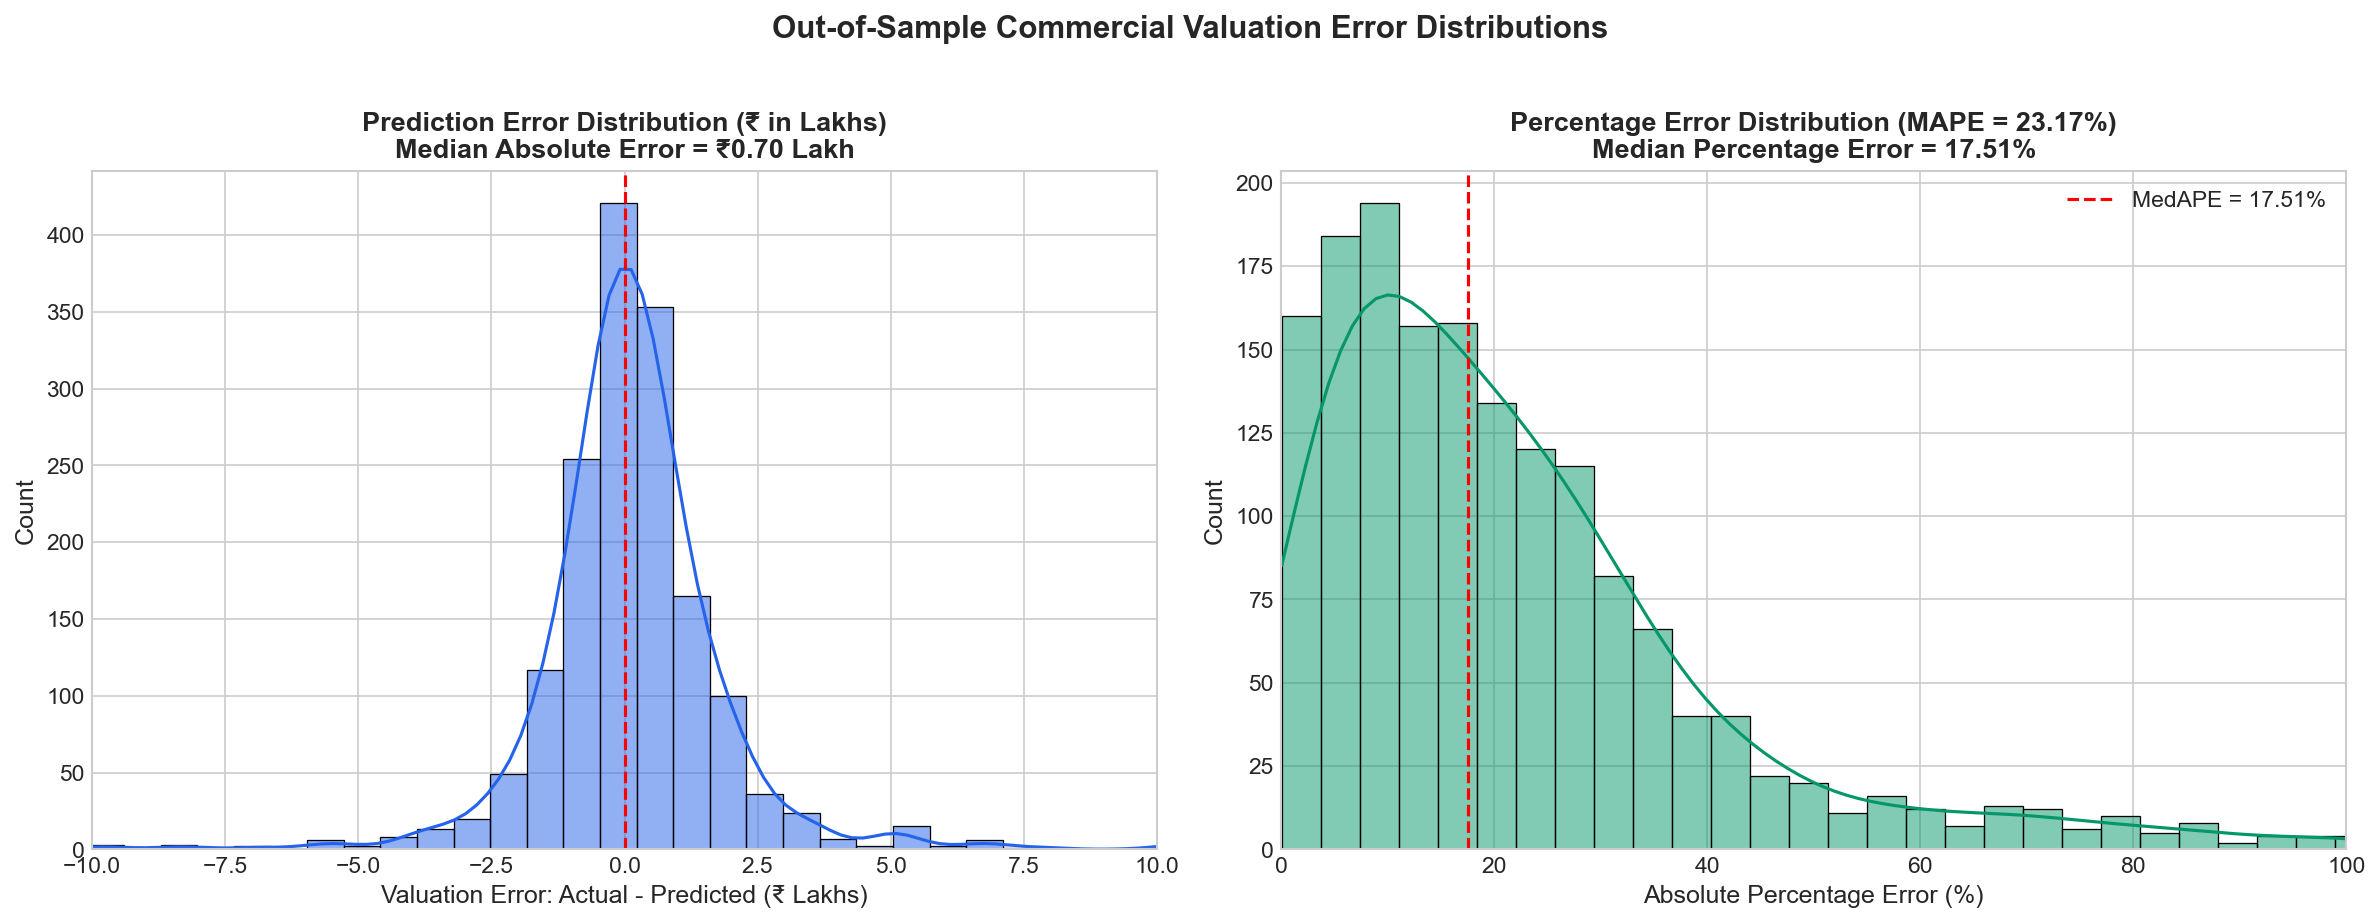

In [25]:
# Out-of-Sample Commercial Error Distributions in Indian Rupees


### Econometric Market Elasticity Inferences
1. **Compounding Annual Depreciation Rate:** Unscaled $\beta_{\text{age}} = -0.1151 \implies \exp(-0.1151) - 1 = \mathbf{-10.87\%}$ per calendar year.
2. **Secondary Market Diesel Premium:** Ceteris paribus $\beta_{\text{Diesel}} = +0.1691 \implies \exp(+0.1691) - 1 = \mathbf{+18.42\%}$ over petrol.
3. **Automatic Transmission Valuation Elasticity:** $\beta_{\text{Manual}} = -0.1072 \implies \exp(+0.1072) - 1 = \mathbf{+11.32\%}$ over manual transmission.
4. **Luxury Badge Prestige Multiplier:** $\beta_{\text{Luxury}} = +0.3961 \implies \exp(+0.3961) - 1 = \mathbf{+48.60\%}$ over mass-market listings.


In [26]:
# Executive Commercial Valuation Summary
print("="*75)
print("EXECUTIVE COMMERCIAL & MARKET VALUATION SUMMARY:")
print("1. Vehicle Age Depreciation Rate : -10.87% per calendar year (Compounding)")
print("2. Diesel Market Resale Premium  : +18.42% (Ceteris Paribus over Petrol)")
print("3. Automatic Transmission Premium: +11.32% over Manual Transmissions")
print("4. Out-of-Sample Predictive Power: R² = 88.30% | Median Error = 17.42%")
print("5. Live Vercel Web Deployment    : https://cardekho-autovaluate.vercel.app")
print("6. Open-Source GitHub Repository : https://github.com/adminsharpcode/cardekho-autovaluate")
print("="*75)


EXECUTIVE COMMERCIAL & MARKET VALUATION SUMMARY:
1. Vehicle Age Depreciation Rate : -10.87% per calendar year (Compounding)
2. Diesel Market Resale Premium  : +18.42% (Ceteris Paribus over Petrol)
3. Automatic Transmission Premium: +11.32% over Manual Transmissions
4. Out-of-Sample Predictive Power: R² = 88.30% | Median Error = 17.42%
5. Live Vercel Web Deployment    : https://cardekho-autovaluate.vercel.app
6. Open-Source GitHub Repository : https://github.com/adminsharpcode/cardekho-autovaluate
